# NB04 — Satellite prediction of Musanga cover fraction from UAV mosaics (V3)

**Objective:** predict Musanga canopy fraction from year-matched Sentinel-2 and annual Google Satellite Embeddings, train across forest sites and evaluate independent site transfer, blocked within-site extrapolation, and annotated-circle transfer at multiple spatial supports.

**Sources:** new frozen NB03 native-RGB M2 full probability maps; V2/08 UAV-acquisition years; V2 native Sentinel-2 10 m projection registry and satellite feature definitions. Source UAV probabilities are *model-derived pseudo-labels*, not independent ground truth. The manually annotated 30 V3 exhaustive circles are an additional diagnostic, but the final M2 that produced pseudo-labels was trained on these circles, so independence is from satellite-model training only, **not** from UAV-model training. Never claim circle comparisons validate UAV probabilities independently.

**Acquisition years from V2:** Baego 2023, Yoko 2020, Yangambi 2024, MOS 2024, optional Luki 2023. **Assumption to verify:** both MOS 3–4 and MOS 5–6 were acquired in the same year as MOS 1–2. Do not interpret within-year temporality as established. Year−1/year/year+1 predictors are retrospective and may contain post-UAV imagery.

**Workflow:** 00 manifest and years → 01 exact S2-aligned grids → 02 begin year-specific satellite downloads (independent of NB03) → 03 aggregate full-UAV probability and thresholded cover with direct source-to-grid area support and coverage masks at 10/20/30/50/75/100 m → 04 build matched predictor/target samples at fixed scales → 05 leave-one-site-out and spatial-block model comparison → 06 independent-annotation-circle diagnostics → 07 diagnostic figures, audit, and best-model refit for satellite maps. Blocks requiring NB03 products stop with an actionable missing-file list; you can download satellite inputs while NB03 runs.

**Analysis distinction:** mean UAV Musanga probability (expected cover) and area fraction of pixels with probability≥0.5 (threshold cover) are separate responses, always with UAV-valid-area fraction. Evaluate both, never label either as field-measured cover. Exclude cells with <90% UAV coverage and near-zero S2 feature support; retain coverage diagnostics. Explicit physical areas and aligned grids are essential, especially 75 m which must be calculated directly (not by stacking 10 m rasters).

**Evaluation contract:** all comparisons use matched geographic cells per scale/family (intersection support); report per-site errors and whole-mosaic maps, and the 30 circle-level observed cover fractions separately. Never randomly split neighboring 10 m pixels: primary leave-one-site-out (Baego/MOS/Yangambi/Yoko; all three MOS mosaics belong to one group); secondary blocked ~500 m grid with ≥100 m spatial buffer and no leakage among overlapping scales. Circle reference polygons and buffers are **excluded from satellite model training** when using pseudo-targets; for site-LOSO, complete held-out site is excluded. Rank models using outer-fold predictions only.

**Start here:** Run setup, grid registry and download cells first. Google Earth Engine authentication must be performed interactively in your Colab account; this notebook cannot authenticate or launch cloud jobs by itself. Downloads are configurable, checkpointed, and never overwrite existing verified raster files.

**V3 mandatory study area:** Only Baego, MOS 1–2, MOS 5–6, Yangambi and Yoko. **MOS 3–4 is excluded.** Every target, training sample, held-out assessment and final satellite prediction is constrained to general `ROI.shp`, never the full orthomosaic bounding box. Full-mosaic aggregates already created are reused for fast ROI clipping into separate outputs, not recalculated.


In [1]:
%pip -q install earthengine-api geemap geedim rasterio geopandas shapely scikit-learn pandas matplotlib scipy tqdm
import json,os,math,hashlib,shutil,time,warnings
from pathlib import Path
import numpy as np,pandas as pd,rasterio
from rasterio.windows import Window
from rasterio.warp import reproject,Resampling,transform_bounds
from affine import Affine
from IPython.display import display
from google.colab import drive
if not Path("/content/drive/MyDrive").exists():drive.mount("/content/drive")
ROOT=next((p for p in [Path("/content/drive/MyDrive/Colab Notebooks/Musanga/Final"),
                         Path("/content/drive/MyDrive/Musanga/Final")] if p.is_dir()),None)
assert ROOT is not None
LEGACY=ROOT.parent/"KVO_work/KVO_08_satellite_fraction"
LEGACY_GRIDS=LEGACY/"validation/09_s2_canonical_10m_grids.json"
MANIFEST=ROOT/"Outputs/V3/00_input_audit/00_input_manifest.json"
assert MANIFEST.exists(),MANIFEST
A=json.loads(MANIFEST.read_text())
assert A.get("schema_version")=="v3_input_audit_5_nadine_circles"
# NB01 scientific contract: five mosaics, four forest groups.
# MOS 3–4 was deliberately excluded from model development/validation.
EXCLUDED_MOSAIC="Mos_3_4_transparent_mosaic_group1_georef.tif"
assert EXCLUDED_MOSAIC in [m["file"] for m in A["mosaics"]]
SOURCES={m["file"]:dict(site=m["site"],path=Path(m["path"]))
         for m in A["mosaics"] if m["file"]!=EXCLUDED_MOSAIC}
assert len(SOURCES)==5 and all(q["path"].exists() for q in SOURCES.values())
assert set(q["site"] for q in SOURCES.values())=={"Baego","MOS","Yangambi","Yoko"}
import geopandas as gpd
from shapely.geometry import box
from shapely.ops import unary_union
ROI_FILE=Path(A["roi"])
assert ROI_FILE.name.casefold()=="roi.shp" and ROI_FILE.exists(),ROI_FILE
ROI_GDF=gpd.read_file(ROI_FILE)
assert ROI_GDF.crs is not None and len(ROI_GDF)>0
assert ROI_GDF.geometry.notna().all() and ROI_GDF.geometry.is_valid.all(),(
    "ROI.shp invalid: use validated V3 NB01 geometries")
ROI_SHA=hashlib.sha256(b"".join(
    (ROI_FILE.with_suffix(ext).read_bytes() if ROI_FILE.with_suffix(ext).exists() else b"")
    for ext in (".shp",".shx",".dbf",".prj"))).hexdigest()
assert ROI_SHA
print("EXCLUDED model mosaic:",EXCLUDED_MOSAIC)
print("Modelling mask:",ROI_FILE,"geometries:",len(ROI_GDF),"SHA:",ROI_SHA[:16])
YEARS={"Baego":2023,"Yoko":2020,"Yangambi":2024,"MOS":2024,"Luki":2023}
PROVENANCE={"Baego":"V2/08","Yoko":"V2/08","Yangambi":"V2/08",
            "MOS":"V2/08 for MOS_1_2; extrapolated provisionally to MOS_3_4/MOS_5_6",
            "Luki":"V2/08; exact acquisition date unresolved"}
INCLUDE_LUKI=False
if INCLUDE_LUKI:
    p=ROOT.parent/"data/Geo_Ref/Luki.tif"
    assert p.exists()
    SOURCES["Luki.tif"]=dict(site="Luki",path=p)
SITES=sorted(set(x["site"] for x in SOURCES.values()))
OUT=ROOT/"Outputs/V3/04_satellite_Musanga"
GRID_DIR=OUT/"grid";FEAT_DIR=OUT/"features";# Preserve previous unmasked aggregation files; new outputs are ROI-specific.
LEGACY_AGG_DIR=OUT/"uav_aggregated"
AGG_DIR=OUT/"uav_aggregated_ROI"
MODEL_DIR=OUT/"models_ROI";QA_DIR=OUT/"qa_ROI"
for p in (GRID_DIR,FEAT_DIR,AGG_DIR,MODEL_DIR,QA_DIR):p.mkdir(parents=True,exist_ok=True)
MODE="final_all30"   # NB03 model, must match native RGB probability maps
NB03=ROOT/("Outputs/V3/03_M2_full_mosaic_"+MODE)/"probability_maps"
THRESHOLD=0.5
MIN_UAV_COVERAGE=.90
MIN_FEATURE_VALID=.90
SCALES=[10,20,30,50,75,100]
assert set(SCALES)=={10,20,30,50,75,100}
assert all(x["site"] in YEARS for x in SOURCES.values())
reg=[]
for m,x in SOURCES.items():
    with rasterio.open(x["path"]) as d:
        assert d.crs is not None
        reg.append(dict(mosaic=m,site=x["site"],year=YEARS[x["site"]],
                        crs=str(d.crs),width=d.width,height=d.height,
                        raster_GB=round(x["path"].stat().st_size/1e9,3),
                        year_basis=PROVENANCE[x["site"]]))
display(pd.DataFrame(reg))
(OUT/"04_input_registry.json").write_text(json.dumps(
    dict(years=YEARS,provenance=PROVENANCE,sources={k:dict(site=v["site"],path=str(v["path"]))
    for k,v in SOURCES.items()},uav_model=MODE,roi=str(ROI_FILE),roi_sha=ROI_SHA,
    excluded_mosaic=EXCLUDED_MOSAIC),indent=2))
print("NB03 files may still be running. Satellite download blocks do not require NB03.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 28.2 MB/s eta 0:00:00
Mounted at /content/drive
EXCLUDED model mosaic: Mos_3_4_transparent_mosaic_group1_georef.tif
Modelling mask: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Ortho_RGB/ROI.shp geometries: 9 SHA: 4f253e1199245a98


,mosaic,site,year,crs,width,height,raster_GB,year_basis
0,Baego.tif,Baego,2023,EPSG:32635,89967,61291,1.193,V2/08
1,Mos_1_2_transparent_mosaic_group1_georef.tif,MOS,2024,EPSG:32635,63924,22137,5.661,V2/08 for MOS_1_2; extrapolated provisionally ...
2,Mos_5_6_transparent_mosaic_group1_georef.tif,MOS,2024,EPSG:32635,31639,39755,5.032,V2/08 for MOS_1_2; extrapolated provisionally ...
3,Yangambi_georef.tif,Yangambi,2024,EPSG:32635,101817,37433,5.428,V2/08
4,Yoko_kvo_georef.tif,Yoko,2020,EPSG:32635,44359,23217,2.198,V2/08


NB03 files may still be running. Satellite download blocks do not require NB03.


## 01 — Canonical 10 m satellite grid and independent 75 m aggregation grids

Use V2's **actual native S2 B2 tile CRS/origin** wherever available. For MOS multi-mosaic analysis, extend a single MOS S2 grid to the union of the mosaics and retain MOS as one cross-validation site. Coarser grids inherit the same UTM origin; 75 m is independent and never formed by averaging prefiltered 10 m pixels.


In [2]:
assert LEGACY_GRIDS.exists(),(
    "V2/08 native Sentinel-2 grid registry missing; build it in V2/08 Block 02 first",LEGACY_GRIDS)
old=json.loads(LEGACY_GRIDS.read_text())
SITE_V2={"Baego":"Baego","Yangambi":"Yangambi","Yoko":"Yoko",
         "MOS":"MOS_1_2","Luki":"Luki"}
GRIDS={}
# Keep the existing exact native-S2 grid for cached satellite products.
# The grid may include pixels outside ROI; all training/evaluation/output maps
# are filtered by independently rasterizing ROI.shp.
def clipped_roi_geometry(site):
    paths=[x["path"] for x in SOURCES.values() if x["site"]==site]
    assert paths,site
    with rasterio.open(paths[0]) as ref:
        crs=ref.crs
    roi=ROI_GDF.to_crs(crs)
    footprints=[]
    for p in paths:
        with rasterio.open(p) as ds:
            assert ds.crs==crs
            footprints.append(box(*ds.bounds))
    geometry=unary_union(list(roi.geometry)).intersection(unary_union(footprints))
    assert not geometry.is_empty and geometry.area>0,(
        "ROI.shp does not intersect retained site mosaics",site)
    return geometry

ROI_BY_SITE={site:clipped_roi_geometry(site) for site in SITES}
def roi_fraction_grid(site,grid,subpixel=4):
    """Fraction of each satellite-scale pixel falling inside eligible ROI.shp."""
    from rasterio.features import rasterize
    import rasterio
    from shapely.geometry import mapping
    crs=grid["crs"]
    with rasterio.open(next(x["path"] for x in SOURCES.values() if x["site"]==site)) as ds:
        geo_crs=ds.crs
    assert str(geo_crs)==crs
    h,w=grid["height"],grid["width"]
    affine=Affine(*grid["transform"])
    # Rasterize only the actual eligible site ROI, not the full image bbox.
    fine=rasterize([(ROI_BY_SITE[site],1)],out_shape=(h*subpixel,w*subpixel),
        transform=affine*Affine.scale(1/subpixel,1/subpixel),
        fill=0,dtype="uint8",all_touched=False)
    return fine.reshape(h,subpixel,w,subpixel).mean(axis=(1,3)).astype("float32")
ROI_MIN_FRACTION=0.90
assert 0<ROI_MIN_FRACTION<=1
for site in SITES:
    key=SITE_V2[site]
    assert key in old,("Missing V2 grid",site,key)
    g=old[key]
    assert int(g["uav_year"])==YEARS[site],(site,g["uav_year"])
    crs=g["uav_crs"]
    # ORIGINAL native scene grid: universal origin for *all* output scales,
    # independent of each site's mosaic footprint.
    native=Affine(*g["native_scene_transform"])
    assert abs(native.a-10)<1e-6 and abs(native.e+10)<1e-6
    assert abs(native.b)<1e-9 and abs(native.d)<1e-9
    rasters=[q["path"] for q in SOURCES.values() if q["site"]==site]
    bounds=[]
    for p in rasters:
        with rasterio.open(p) as ds:
            assert str(ds.crs)==crs,("Mosaic and canonical S2 CRS differ",site,p,ds.crs,crs)
            bounds.append(ds.bounds)
    west=min(b.left for b in bounds);south=min(b.bottom for b in bounds)
    east=max(b.right for b in bounds);north=max(b.top for b in bounds)
    scale=10
    x0=native.c+math.floor((west-native.c)/scale)*scale
    y0=native.f-math.floor((native.f-north)/scale)*scale
    nx=math.ceil((east-x0)/scale);ny=math.ceil((y0-south)/scale)
    GRIDS[site]=dict(site=site,year=YEARS[site],crs=crs,
        native_scene_transform=list(native)[:6],transform=[10,0,x0,0,-10,y0],
        width=nx,height=ny,bounds=[west,south,east,north],
        mosaics=[k for k,q in SOURCES.items() if q["site"]==site],
        scale=10,s2_native_tile=g["s2_native_tile"])
    print(site,"S2 native CRS",crs,"grid",nx,ny,"year",YEARS[site],
          "tile",g["s2_native_tile"])
(OUT/"04_canonical_site_grids.json").write_text(json.dumps(GRIDS,indent=2))

def scaled_grid(site,scale):
    """Exact nested physical UTM grid; does not assume scale divides 10."""
    g=GRIDS[site];native=Affine(*g["native_scene_transform"])
    west,south,east,north=g["bounds"]
    x0=native.c+math.floor((west-native.c)/scale)*scale
    y0=native.f-math.floor((native.f-north)/scale)*scale
    nx=math.ceil((east-x0)/scale);ny=math.ceil((y0-south)/scale)
    return dict(site=site,scale_m=scale,crs=g["crs"],
                transform=[scale,0,x0,0,-scale,y0],width=nx,height=ny)
for scale in SCALES:
    assert all(scaled_grid(s,scale)["width"]>0 for s in SITES)
print("Canonical grids ready. Features can now be downloaded independently of NB03.")


Baego S2 native CRS EPSG:32635 grid 721 491 year 2023 tile 35NLA
MOS S2 native CRS EPSG:32635 grid 784 913 year 2024 tile 35NLA
Yangambi S2 native CRS EPSG:32635 grid 509 187 year 2024 tile 35NKA
Yoko S2 native CRS EPSG:32635 grid 320 166 year 2020 tile 35NKA
Canonical grids ready. Features can now be downloaded independently of NB03.


## 02 — Download annual S2, seasonal S2 and Google annual embeddings (year-matched)

**This block can run while NB03 is producing UAV maps.** Earth Engine access is through the user's authenticated Google Cloud project `musanga-511110`, as in V2. To avoid unexpectedly launching a very large download, default to **Baego annual S2 + annual embeddings** for the first run; add more sites/families after examining QA. The generated outputs are 10 m float32 GeoTIFFs on each site's exact canonical S2 grid, with -9999 NoData, band descriptions and immutable fingerprint/provenance. Existing verified files are reused; incompatible files cause an error rather than overwrite. The download is direct to Colab scratch before verified copy to Drive, using geemap/geedim (V2 approach).

Families: RAW_ANNUAL (10 reflectances + NDVI, NDMI, NBR, NDRE + valid-count), S2_QUARTERLY (4 × 10 reflectances + counts), EMB_ANNUAL (64 Google annual embeddings). Three-year retrospective S2 and embedding families can be added once first acquisition-year exports succeed; do not use future-year imagery in prospective monitoring. No BRDF correction in this first benchmark.


In [10]:
import ee,geemap,geedim
EE_PROJECT="musanga-511110"
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
S2_BANDS=["B2","B3","B4","B8","B5","B6","B7","B8A","B11","B12"]
S2_INDEX=["NDVI","NDMI","NBR","NDRE"]
EMB_BANDS=[f"A{k:02d}" for k in range(64)]
FAMILIES={
 "RAW_ANNUAL":S2_BANDS+S2_INDEX+["N_CLEAR_S2"],
 "S2_QUARTERLY":[f"Q{q}_{band}" for q in range(1,5)
                 for band in S2_BANDS+["N_CLEAR"]],
 "EMB_ANNUAL":EMB_BANDS
}
S2_SOURCE="COPERNICUS/S2_SR_HARMONIZED"
EMB_SOURCE="GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL"
SCL_REJECT=[0,1,3,7,8,9,10,11]
def region(site):
    g=GRIDS[site]
    from rasterio.warp import transform_bounds
    aff=Affine(*g["transform"])
    west=aff.c;south=aff.f-g["height"]*10
    east=aff.c+g["width"]*10;north=aff.f
    b=transform_bounds(g["crs"],"EPSG:4326",west,south,east,north,densify_pts=21)
    return ee.Geometry.Rectangle(list(b),proj="EPSG:4326",geodesic=False)
def clean_s2(im):
    scl=im.select("SCL")
    valid=ee.Image(1)
    for x in SCL_REJECT:valid=valid.And(scl.neq(x))
    valid=valid.And(im.select("B8A").mask()).And(im.select("B9").mask())
    # Preserve native reflectances until post-composite 0.0001 scaling.
    out=ee.Image.cat([im.select(S2_BANDS[:4]),
                      im.select(S2_BANDS[4:]).resample("bilinear")])
    return out.updateMask(valid).copyProperties(im,["system:time_start"])
def add_indices(im):
    return ee.Image.cat([im,
        im.normalizedDifference(["B8","B4"]).rename("NDVI"),
        im.normalizedDifference(["B8","B11"]).rename("NDMI"),
        im.normalizedDifference(["B8","B12"]).rename("NBR"),
        im.normalizedDifference(["B8A","B5"]).rename("NDRE")])
def make_satellite_image(site,family):
    yr=YEARS[site]
    area=region(site)
    if family=="EMB_ANNUAL":
        col=(ee.ImageCollection(EMB_SOURCE)
            .filterDate(f"{yr}-01-01",f"{yr+1}-01-01").filterBounds(area))
        n=int(col.size().getInfo())
        assert n>0,(site,yr,"Annual embedding unavailable")
        return col.mosaic().select(EMB_BANDS).toFloat().clip(area)
    s2=(ee.ImageCollection(S2_SOURCE)
        .filterDate(f"{yr}-01-01",f"{yr+1}-01-01")
        .filterBounds(area).map(clean_s2))
    assert int(s2.size().getInfo())>0,(site,yr,"No S2 SR scenes")
    if family=="RAW_ANNUAL":
        med=s2.median().multiply(.0001)
        count=s2.select("B2").count().unmask(0).toFloat().rename("N_CLEAR_S2")
        return ee.Image.cat([add_indices(med),count]).toFloat().clip(area)
    if family=="S2_QUARTERLY":
        layers=[]
        for quarter in (1,2,3,4):
            first=f"{yr}-{quarter*3-2:02d}-01"
            last=f"{yr+1}-01-01" if quarter==4 else f"{yr}-{quarter*3+1:02d}-01"
            col=s2.filterDate(first,last)
            assert int(col.size().getInfo())>0,(site,yr,quarter,"No seasonal scenes")
            med=col.median().multiply(.0001)
            layers.append(med.rename([f"Q{quarter}_{b}" for b in S2_BANDS]))
            layers.append(col.select("B2").count().unmask(0).toFloat().rename(f"Q{quarter}_N_CLEAR"))
        return ee.Image.cat(layers).toFloat().clip(area)
    raise ValueError(family)

# FIRST RUN: one small controlled feature batch. Expand after success.
DOWNLOAD_SITES= ["Baego", "MOS", "Yangambi", "Yoko"]             # expand to SITES for full study
DOWNLOAD_FAMILIES=["RAW_ANNUAL","EMB_ANNUAL"]  # then S2_QUARTERLY
START_DOWNLOAD=True                    # execute to download; requires Colab+EE auth
assert set(DOWNLOAD_SITES).issubset(SITES)
assert set(DOWNLOAD_FAMILIES).issubset(FAMILIES)
LOCAL_DOWNLOAD=Path("/content/nb04_satellite_download")
LOCAL_DOWNLOAD.mkdir(exist_ok=True)
def feature_path(site,family):
    return FEAT_DIR/family/f"{site}_{family}_{YEARS[site]}_10m.tif"
def feature_ok(path,site,family):
    if not path.exists():return False
    g=GRIDS[site]
    try:
        with rasterio.open(path) as ds:
            return (ds.count==len(FAMILIES[family]) and ds.width==g["width"] and
                ds.height==g["height"] and str(ds.crs)==g["crs"] and
                ds.transform.almost_equals(Affine(*g["transform"]),precision=7) and
                ds.nodata==-9999 and ds.dtypes[0]=="float32" and
                ds.tags().get("FEATURE_FAMILY")==family and
                ds.tags().get("ACQUISITION_YEAR")==str(YEARS[site]))
    except Exception:return False
def download_feature(site,family):
    target=feature_path(site,family)
    target.parent.mkdir(exist_ok=True)
    if target.exists():
        assert feature_ok(target,site,family),("Incompatible old feature; inspect",target)
        print("CACHE HIT",site,family,target,flush=True)
        return
    g=GRIDS[site]
    tmp=LOCAL_DOWNLOAD/f"{site}_{family}_{YEARS[site]}.partial.tif"
    pending=target.with_name(target.name+".uploading")
    assert not pending.exists(),("Interrupted Drive upload; inspect",pending)
    if not tmp.exists():
        image=make_satellite_image(site,family).unmask(-9999,sameFootprint=False).toFloat()
        print("DOWNLOADING",site,family,len(FAMILIES[family]),"bands; grid",
              g["width"],"x",g["height"],flush=True)
        geemap.download_ee_image(
            image,filename=str(tmp),crs=g["crs"],crs_transform=g["transform"],
            shape=(g["height"],g["width"]),dtype="float32",
            resampling="near",max_tile_dim=256,num_threads=1,overwrite=False)
    # Validate *full raster content* and georeferencing before publication.
    with rasterio.open(tmp,"r+") as ds:
        assert ds.count==len(FAMILIES[family]),(site,family,ds.count)
        assert (ds.width,ds.height)==(g["width"],g["height"])
        assert str(ds.crs)==g["crs"] and ds.transform.almost_equals(
            Affine(*g["transform"]),precision=7)
        assert ds.dtypes[0]=="float32"
        for band in range(1,ds.count+1):
            for _,window in ds.block_windows(band):
                val=ds.read(band,window=window)
                assert np.isfinite(val).all(),("NaN/Inf in EE image",site,family,band)
            ds.set_band_description(band,FAMILIES[family][band-1])
        assert ds.nodata in (None,-9999) or (
            ds.nodata is not None and np.isneginf(ds.nodata)),(
            "Unexpected EE NoData",ds.nodata)
        ds.nodata=-9999.
        ds.update_tags(FEATURE_FAMILY=family,ACQUISITION_YEAR=str(YEARS[site]),
                       SOURCE_COLLECTION=S2_SOURCE if family!="EMB_ANNUAL" else EMB_SOURCE,
                       UTM_GRID_SOURCE="V2_08_native_S2_B2",BRDF="NONE",
                       FEATURE_BANDS=json.dumps(FAMILIES[family]))
    assert feature_ok(tmp,site,family)
    shutil.copyfile(tmp,pending)
    assert feature_ok(pending,site,family)
    os.replace(pending,target)
    tmp.unlink(missing_ok=True)
    print("SAVED",site,family,target,flush=True)
if START_DOWNLOAD:
    tasks=[(s,f) for s in DOWNLOAD_SITES for f in DOWNLOAD_FAMILIES]
    for j,(site,family) in enumerate(tasks,1):
        print(f"[{j}/{len(tasks)}] {site} {family}",flush=True)
        download_feature(site,family)
print("Available verified satellite rasters:")
display(pd.DataFrame([dict(site=s,family=f,available=feature_ok(feature_path(s,f),s,f))
                      for s in SITES for f in FAMILIES]))


[1/8] Baego RAW_ANNUAL
CACHE HIT Baego RAW_ANNUAL /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/04_satellite_Musanga/features/RAW_ANNUAL/Baego_RAW_ANNUAL_2023_10m.tif
[2/8] Baego EMB_ANNUAL
CACHE HIT Baego EMB_ANNUAL /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/04_satellite_Musanga/features/EMB_ANNUAL/Baego_EMB_ANNUAL_2023_10m.tif
[3/8] MOS RAW_ANNUAL
DOWNLOADING MOS RAW_ANNUAL 15 bands; grid 784 x 913


/usr/local/lib/python3.13/dist-packages/geemap/common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)
/usr/local/lib/python3.13/dist-packages/geemap/common.py:12334: FutureWarning: 'num_threads' is deprecated and has no effect.  'max_requests' and 'max_cpus' can be used to limit concurrency.
  img.download(filename, overwrite=overwrite, num_threads=num_threads, **kwargs)


  0%|          |0/240 tiles [00:00<?]

/usr/local/lib/python3.13/dist-packages/geedim/image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


SAVED MOS RAW_ANNUAL /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/04_satellite_Musanga/features/RAW_ANNUAL/MOS_RAW_ANNUAL_2024_10m.tif
[4/8] MOS EMB_ANNUAL
DOWNLOADING MOS EMB_ANNUAL 64 bands; grid 784 x 913


...

  0%|          |0/2 tiles [00:00<?]

SAVED Yoko RAW_ANNUAL /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/04_satellite_Musanga/features/RAW_ANNUAL/Yoko_RAW_ANNUAL_2020_10m.tif
[8/8] Yoko EMB_ANNUAL
DOWNLOADING Yoko EMB_ANNUAL 64 bands; grid 320 x 166


  0%|          |0/8 tiles [00:00<?]

SAVED Yoko EMB_ANNUAL /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/04_satellite_Musanga/features/EMB_ANNUAL/Yoko_EMB_ANNUAL_2020_10m.tif
Available verified satellite rasters:


,site,family,available
0,Baego,RAW_ANNUAL,True
1,Baego,S2_QUARTERLY,False
2,Baego,EMB_ANNUAL,True
3,MOS,RAW_ANNUAL,True
4,MOS,S2_QUARTERLY,False
5,MOS,EMB_ANNUAL,True
6,Yangambi,RAW_ANNUAL,True
7,Yangambi,S2_QUARTERLY,False
8,Yangambi,EMB_ANNUAL,True
9,Yoko,RAW_ANNUAL,True


## 03 — Direct native-UAV → target-scale aggregation (10, 20, 30, 50, 75, 100 m)

**Only run when NB03's full-mosaic probability products are complete.** Aggregation is area-weighted. The 10 m target is computed once directly from native UAV data, and **ungated sufficient statistics** (coverage-weighted probability, threshold cover and squared probability) are reduced to nested 20/30/50/100 m grids without rereading native imagery. This is not averaging prefiltered 10 m targets. The 75 m target remains independently derived from native UAV because it does not nest into 10 m. The output for every mosaic×scale contains four float32 bands: mean Musanga probability, fraction of valid native UAV pixels with probability ≥0.50, fraction of total physical cell covered by valid UAV RGB, and within-cell probability standard deviation. Cells with coverage below 90% remain in the product with the coverage diagnostic but are excluded from model sampling. The 75 m raster is created directly on its own S2-origin-aligned grid.

Original UAV probabilities are only predictions from the final native M2, never species polygons or ground-truth fractional cover. MOS 3–4 is an inference-only region; mark it as such and assess transfer carefully. Reprojection uses on-disk derived masks to avoid loading enormous UAV images into Colab RAM. Nothing modifies the source imagery, model outputs, or cached satellite features.

**ROI correction:** MOS 3–4 is excluded. The pipeline masks the existing satellite-scale aggregates to `ROI.shp` and writes them to `uav_aggregated_ROI/`, leaving old full-mosaic rasters intact and avoiding native-UAV reprocessing.


In [11]:
from rasterio.features import rasterize
from rasterio.warp import reproject
NODATA_U16=65535
SCALE_U16=10000
TARGET_NAMES=["p_mean","cover_fraction_p05","uav_valid_fraction","p_sd"]
WORK=Path("/content/nb04_aggregate_work");WORK.mkdir(exist_ok=True)
RUN_AGGREGATION=True
AGG_SITES=list(SITES)  # optionally ['Baego'] for a first pilot

def uav_probability_file(name):
    stem=Path(name).stem
    return NB03/f"{stem}_M2_{MODE}_probability_u16_FULL.tif"

def agg_file(mosaic,scale):
    return AGG_DIR/f"{Path(mosaic).stem}_M2_{MODE}_{scale}m.tif"

def target_spec(name,scale,src):
    grid=scaled_grid(SOURCES[name]["site"],scale)
    return dict(mosaic=name,site=SOURCES[name]["site"],scale_m=scale,
        source_path=str(uav_probability_file(name)),
        source_key=src.tags().get("SPEC"),target_grid=grid,
        threshold=THRESHOLD,uav_scale=SCALE_U16,uav_nodata=NODATA_U16,
        pipeline="NB04_native_direct_area_average_v1")

def band_profile(src,dtype,nodata):
    kw=src.profile.copy()
    for field in ("photometric","alpha","extrasamples","NBITS","colorinterp","interleave"):
        kw.pop(field,None)
    kw.update(driver="GTiff",count=1,dtype=dtype,nodata=nodata,
              tiled=True,blockxsize=256,blockysize=256,compress=None,
              bigtiff="YES",SPARSE_OK=False)
    return kw

def create_derived_native_layers(src,workdir):
    """Temporary on-disk 0/1 validity and native p≥0.5 masks.

    Invalid RGB is 0 in validity; invalid is 255 (NoData) in cover.
    Sources are processed in native block windows, never held entirely in RAM.
    """
    valid_path=workdir/"valid_native.tif"
    cover_path=workdir/"cover_native.tif"
    sq_path=workdir/"probability_squared_native.tif"
    valid_profile=band_profile(src,"uint8",None)
    cover_profile=band_profile(src,"uint8",255)
    sq_profile=band_profile(src,"float32",-9999)
    with rasterio.open(valid_path,"w",**valid_profile) as vd,\
         rasterio.open(cover_path,"w",**cover_profile) as cv,\
         rasterio.open(sq_path,"w",**sq_profile) as sq:
        for _,window in src.block_windows(1):
            a=src.read(1,window=window)
            ok=a!=NODATA_U16
            vd.write(ok.astype("uint8"),1,window=window)
            mask=np.full(a.shape,255,"uint8")
            mask[ok]=(a[ok]>=round(THRESHOLD*SCALE_U16)).astype("uint8")
            cv.write(mask,1,window=window)
            p2=np.full(a.shape,-9999,"float32")
            p2[ok]=(a[ok].astype("float32")/SCALE_U16)**2
            sq.write(p2,1,window=window)
    return valid_path,cover_path,sq_path

def aggregate_one(name,scale,local_source=None):
    source=uav_probability_file(name)
    assert source.exists(),("NB03 not finished for this source",name,source)
    output=agg_file(name,scale)
    with rasterio.open(local_source or source) as src:
        assert src.dtypes[0]=="uint16" and src.nodata==NODATA_U16,(name,src.dtypes,src.nodata)
        assert src.tags().get("COMPLETE")=="YES",(name,"NB03 output not finalized")
        spec=target_spec(name,scale,src)
        spec_sha=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()
        grid=spec["target_grid"]
        trans=Affine(*grid["transform"])
        if output.exists():
            with rasterio.open(output) as old:
                assert old.tags().get("SPEC_SHA")==spec_sha and old.count==4
            print("AGG CACHE HIT",name,scale,flush=True)
            return output
        sitework=WORK/Path(name).stem
        sitework.mkdir(exist_ok=True)
        # Reuse temporary native masks across scales in the current session.
        validfile,coverfile,sqfile=[sitework/x for x in (
            "valid_native.tif","cover_native.tif","probability_squared_native.tif")]
        if not all(p.exists() for p in (validfile,coverfile,sqfile)):
            for p in (validfile,coverfile,sqfile):p.unlink(missing_ok=True)
            create_derived_native_layers(src,sitework)
        assert all(p.exists() for p in (validfile,coverfile,sqfile))
        shape=(grid["height"],grid["width"])
        assert shape[0]*shape[1]<150_000_000,("Oversized grid: do spatial chunking",name,scale,shape)
        def warp(source_band,source_nodata,dest_nodata=-9999):
            dest=np.full(shape,dest_nodata,"float32")
            reproject(source=source_band,destination=dest,
                src_transform=src.transform,src_crs=src.crs,
                src_nodata=source_nodata,dst_transform=trans,dst_crs=grid["crs"],
                dst_nodata=dest_nodata,resampling=Resampling.average,
                num_threads=2,warp_mem_limit=256)
            return dest
        p=warp(rasterio.band(src,1),NODATA_U16)
        p=np.where(p==-9999,-9999,p/SCALE_U16)
        with rasterio.open(validfile) as valid_src,\
             rasterio.open(coverfile) as cover_src,\
             rasterio.open(sqfile) as sq_src:
            coverage=warp(rasterio.band(valid_src,1),None)
            cover=warp(rasterio.band(cover_src,1),255)
            sq=warp(rasterio.band(sq_src,1),-9999)
        coverage=np.clip(coverage,0,1)
        defined=(p!=-9999)&(cover!=-9999)&(sq!=-9999)&(coverage>0)
        sd=np.full(shape,-9999,"float32")
        sd[defined]=np.sqrt(np.maximum(0,sq[defined]-p[defined]**2))
        desc=dict(driver="GTiff",height=shape[0],width=shape[1],count=4,
            crs=grid["crs"],transform=trans,dtype="float32",nodata=-9999,
            tiled=True,blockxsize=256,blockysize=256,compress="deflate",
            predictor=3,bigtiff="YES")
        partial=output.with_name(output.name+".partial.tif")
        with rasterio.open(partial,"w",**desc) as dst:
            for idx,layer in enumerate((p,cover,coverage,sd),1):
                dst.write(layer.astype("float32"),idx)
                dst.set_band_description(idx,TARGET_NAMES[idx-1])
            dst.update_tags(SPEC_SHA=spec_sha,DATA_SOURCE=str(source),
                UAV_PROBABILITY_MODEL=MODE,AGGREGATION="NATIVE_DIRECT_AVERAGE",
                MIN_VALID_COVERAGE=str(MIN_UAV_COVERAGE),COMPLETE="YES")
        assert partial.exists()
        os.replace(partial,output)
        print("AGG SAVED",name,scale,"grid",shape,"supported",
              int(np.sum(defined&(coverage>=MIN_UAV_COVERAGE))),flush=True)
        return output


def aggregate_from_10m(name,scale):
    """Fast exact-area nested aggregation of unthresholded 10m sufficient statistics.
    Works only when coarse scale is an integer multiple of native S2 10m grid.
    The 90% UAV coverage threshold is NOT applied at the 10m stage.
    """
    assert scale>10 and scale%10==0,("75m needs native direct pass",scale)
    base=agg_file(name,10)
    assert base.exists(),("Complete the 10m reference once first",base)
    output=agg_file(name,scale)
    source=uav_probability_file(name)
    with rasterio.open(source) as src:
        assert src.tags().get("COMPLETE")=="YES"
        spec=target_spec(name,scale,src)
    spec_sha=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()
    if output.exists():
        with rasterio.open(output) as prev:
            assert prev.count==4 and prev.tags().get("SPEC_SHA")==spec_sha
        print("AGG CACHE HIT",name,scale,flush=True)
        return output
    grid=spec["target_grid"]
    shape=(grid["height"],grid["width"])
    trans=Affine(*grid["transform"])
    with rasterio.open(base) as ds:
        assert ds.count==4 and ds.tags().get("COMPLETE")=="YES"
        p,cover,cov,sd=ds.read().astype("float32")
        # Preserve all 10m observations, including those with <90% coverage.
        v=(cov>0)&np.isfinite(cov)&(p>=0)&(p<=1)&(cover>=0)&(cover<=1)&(sd>=0)
        w=np.where(v,np.clip(cov,0,1),0).astype("float32")
        p=np.where(v,p,0).astype("float32")
        cover=np.where(v,cover,0).astype("float32")
        sd=np.where(v,sd,0).astype("float32")
        moments=[w,w*p,w*cover,w*(p*p+sd*sd)]
        def area_avg(a):
            dst=np.zeros(shape,"float32")
            reproject(source=a,destination=dst,src_transform=ds.transform,
                src_crs=ds.crs,src_nodata=None,dst_transform=trans,
                dst_crs=grid["crs"],dst_nodata=None,
                resampling=Resampling.average,num_threads=2,warp_mem_limit=64)
            return dst
        cw,cp,cc,cp2=[area_avg(a) for a in moments]
    supported=cw>1e-8
    pm=np.full(shape,-9999,"float32")
    cm=np.full(shape,-9999,"float32")
    sdout=np.full(shape,-9999,"float32")
    pm[supported]=np.clip(cp[supported]/cw[supported],0,1)
    cm[supported]=np.clip(cc[supported]/cw[supported],0,1)
    sdout[supported]=np.sqrt(np.maximum(0,
                   cp2[supported]/cw[supported]-pm[supported]**2))
    coverage=np.clip(cw,0,1).astype("float32")
    profile=dict(driver="GTiff",height=shape[0],width=shape[1],count=4,
        crs=grid["crs"],transform=trans,dtype="float32",nodata=-9999,
        tiled=True,blockxsize=256,blockysize=256,compress="deflate",
        predictor=3,bigtiff="YES")
    partial=output.with_name(output.name+".partial.tif")
    with rasterio.open(partial,"w",**profile) as dst:
        for i,a in enumerate((pm,cm,coverage,sdout),1):
            dst.write(a, i)
            dst.set_band_description(i,TARGET_NAMES[i-1])
        dst.update_tags(SPEC_SHA=spec_sha,DATA_SOURCE=str(source),
            UAV_PROBABILITY_MODEL=MODE,AGGREGATION="10M_UNFILTERED_MOMENT_REDUCTION",
            MIN_VALID_COVERAGE=str(MIN_UAV_COVERAGE),COMPLETE="YES")
    os.replace(partial,output)
    print("AGG FAST",name,scale,"supported",
          int((supported&(coverage>=MIN_UAV_COVERAGE)).sum()),flush=True)
    return output

# Efficient V3 modelling subset: reuse previously generated full-mosaic
# satellite-scale target rasters, crop to ROI.shp, and NEVER aggregate MOS 3–4.
# The legacy rasters are not changed or deleted.
RUN_AGGREGATION=True
RUN_MISSING_NATIVE=False  # safety: never trigger multi-minute native warps implicitly

def legacy_agg_file(name,scale):
    return LEGACY_AGG_DIR/f"{Path(name).stem}_M2_{MODE}_{scale}m.tif"

def roi_agg_from_legacy(name,scale):
    existing=legacy_agg_file(name,scale)
    output=agg_file(name,scale)
    if not existing.exists():
        return None
    site=SOURCES[name]["site"]
    grid=scaled_grid(site,scale)
    signature=dict(source=str(existing),source_bytes=existing.stat().st_size,
                   source_mtime_ns=existing.stat().st_mtime_ns,
                   roi_sha=ROI_SHA,roi_fraction_min=ROI_MIN_FRACTION,
                   site=site,scale=scale,geometry="ROI_shp_intersect_retained_mosaic_footprints",
                   version="NB04_ROI_MODEL_v1")
    key=hashlib.sha256(json.dumps(signature,sort_keys=True).encode()).hexdigest()
    if output.exists():
        with rasterio.open(output) as old:
            assert old.tags().get("ROI_SPEC_SHA")==key and old.count==4,(
                "Previously generated ROI raster differs from current inputs",output)
        print("ROI CACHE HIT",name,scale,flush=True)
        return output
    with rasterio.open(existing) as src:
        assert src.count==4 and src.tags().get("COMPLETE")=="YES",existing
        assert str(src.crs)==grid["crs"]
        assert src.transform.almost_equals(Affine(*grid["transform"]),precision=7)
        assert (src.height,src.width)==(grid["height"],grid["width"])
        # Small satellite grid only. The native UAV mosaic is NOT read.
        data=src.read().astype("float32")
        profile=src.profile.copy()
    fraction=roi_fraction_grid(site,grid)
    eligible=fraction>=ROI_MIN_FRACTION
    # Exclude pixels outside ROI from all reported bands, not merely at training.
    data[:,~eligible]=-9999.
    # Valid coverage fraction inside the ROI is distinct from the ROI area
    # fraction; strict >=90% ROI containment avoids ambiguous boundary cells.
    partial=output.with_name(output.name+".partial.tif")
    with rasterio.open(partial,"w",**profile) as dst:
        dst.write(data)
        for j,label in enumerate(TARGET_NAMES,1):
            dst.set_band_description(j,label)
        dst.update_tags(ROI_SPEC_SHA=key,ROI_SOURCE=str(ROI_FILE),
            ROI_SHA=ROI_SHA,ROI_MIN_FRACTION=str(ROI_MIN_FRACTION),
            EXCLUDED_MOSAIC=EXCLUDED_MOSAIC,COMPLETE="YES",
            ROI_ELIGIBLE_CELLS=str(int(eligible.sum())),
            AGGREGATION_SOURCE="PRECOMPUTED_SATELLITE_SCALE_UNGATED",
            TARGET_OUTSIDE_ROI="NODATA")
    os.replace(partial,output)
    valid=(eligible&(data[2]>=MIN_UAV_COVERAGE))
    print("ROI AGG SAVED",name,scale,
          "ROI cells",int(eligible.sum()),"supported",int(valid.sum()),flush=True)
    return output

if RUN_AGGREGATION:
    assert EXCLUDED_MOSAIC not in SOURCES
    todo=[]
    completed=0
    for name in SOURCES:
        for scale in SCALES:
            produced=roi_agg_from_legacy(name,scale)
            if produced is None:
                todo.append((name,scale,str(legacy_agg_file(name,scale))))
            else:
                completed+=1
    print("ROI-masked products available:",completed,"pending legacy aggregations:",len(todo))
    if todo:
        display(pd.DataFrame(todo,columns=["mosaic","scale_m","legacy_target"]))
        print("Unmasked aggregates missing: complete original aggregation only if needed. "
              "No full-resolution operation was started by this cell.",flush=True)
    if RUN_MISSING_NATIVE and todo:
        raise NotImplementedError(
            "Do not initiate slow full-UAV aggregation from this ROI-only modelling notebook; "
            "first produce missing scales in the original aggregation pipeline, then rerun.")


ROI CACHE HIT Baego.tif 10
ROI CACHE HIT Baego.tif 20
ROI CACHE HIT Baego.tif 30
ROI CACHE HIT Baego.tif 50
ROI CACHE HIT Baego.tif 75
ROI CACHE HIT Baego.tif 100
ROI CACHE HIT Mos_1_2_transparent_mosaic_group1_georef.tif 10
ROI CACHE HIT Mos_1_2_transparent_mosaic_group1_georef.tif 20
ROI CACHE HIT Mos_1_2_transparent_mosaic_group1_georef.tif 30
ROI CACHE HIT Mos_1_2_transparent_mosaic_group1_georef.tif 50
ROI CACHE HIT Mos_1_2_transparent_mosaic_group1_georef.tif 75
ROI CACHE HIT Mos_1_2_transparent_mosaic_group1_georef.tif 100
ROI CACHE HIT Mos_5_6_transparent_mosaic_group1_georef.tif 10
ROI CACHE HIT Mos_5_6_transparent_mosaic_group1_georef.tif 20
ROI CACHE HIT Mos_5_6_transparent_mosaic_group1_georef.tif 30
ROI CACHE HIT Mos_5_6_transparent_mosaic_group1_georef.tif 50
ROI CACHE HIT Mos_5_6_transparent_mosaic_group1_georef.tif 75
ROI CACHE HIT Mos_5_6_transparent_mosaic_group1_georef.tif 100
ROI CACHE HIT Yangambi_georef.tif 10
ROI CACHE HIT Yangambi_georef.tif 20
ROI CACHE HIT Yan

## 04 — Matched satellite predictors and target samples, with all annotated circles excluded from model fitting

For each site/mosaic/scale, aggregate each available satellite predictor band from the original 10 m S2 grid to the **same geographic footprint as the UAV target** using area-weighted averaging. Rows are keyed by UTM coordinates and cell resolution, not pixel row from a different raster. A separate full-mosaic target-support table records valid coverage. **Every 30-circle footprint plus a 100 m exclusion buffer is removed from satellite model training**, ensuring that the circle comparison is not contaminated by satellite training pixels. The circles remain available for independent satellite evaluation in Section 06.

Site-level duplicates in overlapping MOS mosaics are deduplicated by retaining the highest UAV-valid coverage. Random sampling is deterministic but **is only for managing memory**, never the validation split. Use one fixed sample inventory per site and scale; compare feature families on the exact same sampled geographic cells when possible.


In [12]:
%pip -q install pyarrow
import geopandas as gpd
from rasterio.features import rasterize
from shapely.geometry import box
from rasterio.windows import transform as window_transform
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit

LINKS_FILE=ROOT/"Outputs/V3/01_reference_data_no_MOS34/01_circle_spatial_folds.csv"
assert LINKS_FILE.exists()
links=pd.read_csv(LINKS_FILE)
assert len(links)==30 and links.circle_id.is_unique
CIRCLE_FILE=Path(A["exhaustive_annotations"]["complete_roi_boundaries"])
assert CIRCLE_FILE.exists()
ALL_CIRCLES=gpd.read_file(CIRCLE_FILE)
assert max(links.circle_id)<len(ALL_CIRCLES)
SAMPLE_SCALES=[10,30,50,75,100]  # exploratory, supports 20m too
SAMPLE_FAMILIES=list(FAMILIES)
MAX_CELLS_PER_MOSAIC=18000
BUFFER_CIRCLE_M=100
SPATIAL_BLOCK_M=500
BLOCK_BUFFER_M=100
SAMPLE_DIR=OUT/"samples_ROI";SAMPLE_DIR.mkdir(exist_ok=True)
SEED04=20261019
def selected_circle_geoms(site):
    a=links[links.site==site].copy()
    with rasterio.open(next(q["path"] for q in SOURCES.values() if q["site"]==site)) as ds:
        g=ALL_CIRCLES.iloc[a.circle_id.astype(int)].to_crs(ds.crs)
    return g.geometry
def circle_exclusion_mask(site,grid):
    shapes=[(g.buffer(BUFFER_CIRCLE_M),1) for g in selected_circle_geoms(site)
            if g is not None and not g.is_empty]
    if not shapes:return np.zeros((grid["height"],grid["width"]),dtype=bool)
    return rasterize(shapes,out_shape=(grid["height"],grid["width"]),
        transform=Affine(*grid["transform"]),fill=0,dtype="uint8").astype(bool)

def feature_on_grid(site,family,grid):
    """Area average original 10m feature bands onto a target-scale *physical* grid."""
    srcfile=feature_path(site,family)
    if not feature_ok(srcfile,site,family):return None
    arr=np.full((len(FAMILIES[family]),grid["height"],grid["width"]),np.nan,"float32")
    transform=Affine(*grid["transform"])
    with rasterio.open(srcfile) as ds:
        for b in range(1,ds.count+1):
            a=np.full((grid["height"],grid["width"]),-9999,"float32")
            reproject(rasterio.band(ds,b),a,src_transform=ds.transform,
                src_crs=ds.crs,src_nodata=-9999,
                dst_transform=transform,dst_crs=grid["crs"],dst_nodata=-9999,
                resampling=Resampling.average,num_threads=2,warp_mem_limit=192)
            a[a==-9999]=np.nan
            arr[b-1]=a
    return arr

def create_samples(site,scale):
    dest=SAMPLE_DIR/f"{site}_{scale}m_samples.parquet"
    meta=SAMPLE_DIR/f"{site}_{scale}m_samples.json"
    available=[f for f in SAMPLE_FAMILIES if feature_ok(feature_path(site,f),site,f)]
    assert available,("Download at least one satellite feature family",site)
    files=[(name,agg_file(name,scale)) for name,q in SOURCES.items() if q["site"]==site]
    assert all(p.exists() for _,p in files),("Aggregate UAV maps first",site,scale)
    grid=scaled_grid(site,scale)
    # Prevent accidental reuse if new satellite files are added.
    ident=dict(site=site,scale=scale,source_files={
        str(p):dict(bytes=p.stat().st_size,mtime_ns=p.stat().st_mtime_ns)
        for p in [q for _,q in files]+[feature_path(site,f) for f in available]},
        families=available,buffer=BUFFER_CIRCLE_M,cap=MAX_CELLS_PER_MOSAIC,
        sample_seed=SEED04,target=MODE,roi_sha=ROI_SHA,
        roi_min_fraction=ROI_MIN_FRACTION,excluded_mosaic=EXCLUDED_MOSAIC)
    key=hashlib.sha256(json.dumps(ident,sort_keys=True).encode()).hexdigest()
    if dest.exists() and meta.exists():
        old=json.loads(meta.read_text())
        if old["key"]==key:
            return pd.read_parquet(dest)
    features={f:feature_on_grid(site,f,grid) for f in available}
    excluded=circle_exclusion_mask(site,grid)
    roi_keep=roi_fraction_grid(site,grid)>=ROI_MIN_FRACTION
    full=[]
    trans=Affine(*grid["transform"])
    for name,path in files:
        with rasterio.open(path) as ds:
            assert ds.count==4 and ds.transform.almost_equals(trans,precision=8)
            target=ds.read().astype("float32")
            assert ds.tags().get("ROI_SHA")==ROI_SHA, (
                "Expected ROI-masked target, not full-mosaic aggregate",path)
        ok=(target[2]>=MIN_UAV_COVERAGE)&(target[0]>=0)&(target[0]<=1)&roi_keep
        r,c=np.where(ok)
        if len(r)==0:continue
        # Do not bias sample selection by prediction values. Uniform spatial sample.
        rng=np.random.default_rng(SEED04+scale+sum(map(ord,name)))
        if len(r)>MAX_CELLS_PER_MOSAIC:
            choose=rng.choice(len(r),MAX_CELLS_PER_MOSAIC,replace=False)
            r=r[choose];c=c[choose]
        # Physical cell-centre coordinates on the shared UTM grid.
        x=trans.c+(c+.5)*trans.a
        y=trans.f+(r+.5)*trans.e
        d=pd.DataFrame(dict(site=site,mosaic=name,scale_m=scale,
              row=r,col=c,x=x,y=y,uav_probability=target[0,r,c],
              uav_cover=target[1,r,c],uav_valid=target[2,r,c],
              exclude_circles=excluded[r,c],
              block_x=np.floor(x/SPATIAL_BLOCK_M).astype("int64"),
              block_y=np.floor(y/SPATIAL_BLOCK_M).astype("int64")))
        for family,arr in features.items():
            for i,colname in enumerate(FAMILIES[family]):
                d[f"{family}__{colname}"]=arr[i,r,c]
        full.append(d)
    assert full,("No valid aggregated training support",site,scale)
    table=pd.concat(full,ignore_index=True)
    # All MOS mosaics belong to one site. Never count same geographic cells twice.
    table=table.sort_values("uav_valid",ascending=False)
    table=table.drop_duplicates(["site","scale_m","row","col"],keep="first")
    table["block_id"]=table.block_x.astype(str)+"_"+table.block_y.astype(str)
    table.to_parquet(dest,index=False)
    meta.write_text(json.dumps(dict(key=key,contract=ident,n=len(table),
             usable_for_training=int((~table.exclude_circles).sum())),indent=2))
    print("SAMPLES",site,scale,len(table),"train eligible",
          int((~table.exclude_circles).sum()),"families",available,flush=True)
    return table

# Optional: generate only for features and sites already downloaded/aggregated.
RUN_SAMPLE_BUILDER=True
AVAILABLE_SITES=[site for site in SITES if all(
    agg_file(name,10).exists() for name,x in SOURCES.items() if x["site"]==site)
    and any(feature_ok(feature_path(site,f),site,f) for f in FAMILIES)]
if RUN_SAMPLE_BUILDER:
    for scale in SAMPLE_SCALES:
        for site in AVAILABLE_SITES:
            if all(agg_file(name,scale).exists() for name,x in SOURCES.items() if x["site"]==site):
                create_samples(site,scale)
print("Sample sites currently available:",AVAILABLE_SITES)


SAMPLES MOS 10 36000 train eligible 34846 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yangambi 10 18000 train eligible 13002 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yoko 10 18000 train eligible 13020 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES MOS 30 28630 train eligible 27737 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yangambi 30 3962 train eligible 2847 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yoko 30 3122 train eligible 2251 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES MOS 50 11520 train eligible 11170 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yangambi 50 1378 train eligible 986 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yoko 50 1095 train eligible 781 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES MOS 75 5077 train eligible 4921 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yangambi 75 576 train eligible 415 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES Yoko 75 475 train eligible 335 families ['RAW_ANNUAL', 'EMB_ANNUAL']
SAMPLES MOS 100 2805 train eligible 

## 05 — Spatially independent model comparison: site LOSO first, blocked within-site second

**Primary outer validation:** leave out **all mosaics at one site** (four folds: Baego, MOS, Yangambi, Yoko), train on the other sites' off-circle pseudo-label cells. Site-balanced sampling prevents the multiple MOS mosaics from dominating the fit. Report R², MAE, RMSE, bias and number of independent 500 m blocks; pixel-level cell counts are not independent replicates. Compare annual Sentinel-2, quarterly S2, annual embeddings, RAW+embedding and RAW+quarterly+embedding **on the same geographic site-cell subset for each requested comparison**. Report the number of evaluable sites/cells and do not use a family unless the necessary feature rasters exist for every site in that comparison.

**Secondary within-site validation:** split whole 500 m UTM blocks and exclude training samples within **100 m** of validation blocks. This tests local extrapolation only; it should not be confused with completely new-site transfer. For varying aggregation resolutions, always recompute the independent model at that scale, and compare scales using site-level summaries; spatially correlated 10 m cells cannot be treated as 100× more replication than 100 m cells.

**Evaluation products:** cell-level held-out predictions, site-scale metric tables, and full-site held-out prediction GeoTIFFs (two bands: expected probability-derived Musanga fraction and threshold-cover fraction). These satellite rasters may extend beyond UAV mosaic footprints, but scored regions require ≥90% observed native UAV support. Models are saved with configuration, sites and feature-column contract.


In [14]:
import joblib
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupShuffleSplit
TARGETS={"prob":"uav_probability","cover":"uav_cover"}
FEATURE_COMBINATIONS={
    "RAW":["RAW_ANNUAL"],
    "QUARTERLY":["S2_QUARTERLY"],
    "EMBEDDING":["EMB_ANNUAL"],
    "RAW_EMBEDDING":["RAW_ANNUAL","EMB_ANNUAL"],
    "RAW_QUARTERLY_EMBEDDING":["RAW_ANNUAL","S2_QUARTERLY","EMB_ANNUAL"]
}
MAX_TRAIN_SITE=9000
MAX_TEST_SITE=18000
BENCHMARK_SCALES=[10,30,50,75,100]
BENCHMARK_FAMILIES=list(FEATURE_COMBINATIONS)
def get_columns(families):
    return [f"{f}__{c}" for f in families for c in FAMILIES[f]]
def fitted_model():
    # Fixed a priori; no tuning on heldout data.
    return HistGradientBoostingRegressor(
        loss="squared_error",learning_rate=.06,max_iter=200,
        max_leaf_nodes=20,min_samples_leaf=40,l2_regularization=2,
        early_stopping=False,random_state=SEED04)

def balanced_rows(frame,n,seed):
    if len(frame)<=n:return frame
    return frame.sample(n=n,random_state=seed).copy()

def regression_metrics(reference,prediction,site,scale,family,target,kind,blocks):
    y=np.asarray(reference,"float64");p=np.asarray(prediction,"float64")
    assert len(y)==len(p) and len(y)>0
    return dict(site=site,scale_m=scale,family=family,target=target,
        validation=kind,n_cells=len(y),n_spatial_blocks=blocks,
        R2=float(r2_score(y,p)) if len(y)>1 else np.nan,
        MAE_pp=float(100*mean_absolute_error(y,p)),
        RMSE_pp=float(100*np.sqrt(mean_squared_error(y,p))),
        bias_pp=float(100*np.mean(p-y)))

def _feature_grid(site,scale,families):
    grid=scaled_grid(site,scale)
    cubes=[]
    for f in families:
        a=feature_on_grid(site,f,grid)
        if a is None:return None
        cubes.append(a)
    return np.concatenate(cubes,axis=0),grid

def save_oof_site_maps(site,scale,family,target_models,features):
    cube,grid=features
    mask=np.all(np.isfinite(cube),axis=0) & (
        roi_fraction_grid(site,grid)>=ROI_MIN_FRACTION)
    loc=np.where(mask.ravel())[0]
    out=np.full((2,grid["height"]*grid["width"]),-9999,dtype="float32")
    flat=cube.reshape(cube.shape[0],-1)
    for offset in range(0,len(loc),30000):
        ids=loc[offset:offset+30000]
        X=flat[:,ids].T
        for i,kind in enumerate(("prob","cover")):
            out[i,ids]=np.clip(target_models[kind].predict(X),0,1)
    path=MODEL_DIR/f"oof_{family}_{site}_{scale}m.tif"
    kw=dict(driver="GTiff",height=grid["height"],width=grid["width"],
            count=2,dtype="float32",crs=grid["crs"],
            transform=Affine(*grid["transform"]),nodata=-9999,
            tiled=True,blockxsize=256,blockysize=256,compress="deflate",
            predictor=3,bigtiff="YES")
    assert not path.exists(),("Existing OOF map: preserve and check run identity",path)
    with rasterio.open(path,"w",**kw) as dst:
        dst.write(out.reshape(2,grid["height"],grid["width"]))
        dst.set_band_description(1,"predicted_mean_Musanga_probability")
        dst.set_band_description(2,"predicted_Musanga_cover_fraction_p05")
        dst.update_tags(VALIDATION="SITE_HELD_OUT",SITE=site,FAMILY=family,
                        SCALE_M=str(scale),COMPLETE="YES")
    return path

def run_site_loso(scale,family,write_maps=True):
    fams=FEATURE_COMBINATIONS[family]
    cols=get_columns(fams)
    frames={}
    for site in SITES:
        p=SAMPLE_DIR/f"{site}_{scale}m_samples.parquet"
        if not p.exists():continue
        d=pd.read_parquet(p)
        if all(c in d.columns for c in cols):
            frames[site]=d
    if len(frames)<3:
        print("DEFER LOSO",scale,family,"need at least 3 sites, have",sorted(frames),flush=True)
        return [],[]
    if set(frames)!=set(SITES):
        print("PARTIAL LOSO",scale,family,"sites",sorted(frames),
              "- not a complete 4/5-site benchmark",flush=True)
    # Use the same source-pixel support across families whenever those families
    # are available at all included sites. Missing bands cannot improve a
    # model simply by dropping the hard-to-predict cells from evaluation.
    common_families=[fam for fam in FEATURE_COMBINATIONS
        if all(all(c in d.columns for c in get_columns(FEATURE_COMBINATIONS[fam]))
               for d in frames.values())]
    common_cols=sorted(set(c for fam in common_families
                    for c in get_columns(FEATURE_COMBINATIONS[fam])))
    assert set(cols).issubset(set(common_cols))
    rows=[];pred_rows=[]
    for hold in sorted(frames):
        train_list=[]
        for site in sorted(frames):
            if site==hold:continue
            d=frames[site]
            d=d.loc[~d.exclude_circles].dropna(subset=common_cols+list(TARGETS.values()))
            train_list.append(balanced_rows(d,MAX_TRAIN_SITE,SEED04+scale))
        train=pd.concat(train_list,ignore_index=True)
        test=frames[hold].dropna(subset=cols+list(TARGETS.values()))
        test=balanced_rows(test,MAX_TEST_SITE,SEED04+scale+23)
        if len(train)<200 or len(test)<30:
            print("DEFER",hold,scale,family,"too few samples",len(train),len(test))
            continue
        assert set(train.site).isdisjoint(set(test.site))
        Xtrain=train[cols].to_numpy("float32")
        Xtest=test[cols].to_numpy("float32")
        fitted={}
        for typ,ycol in TARGETS.items():
            model=fitted_model()
            model.fit(Xtrain,train[ycol].to_numpy("float32"))
            prediction=np.clip(model.predict(Xtest),0,1)
            blocks=test.block_id.nunique()
            rows.append(regression_metrics(test[ycol],prediction,hold,
                 scale,family,typ,"LOSO",blocks))
            if typ=="prob":record=test[["site","mosaic","scale_m","row","col","x","y",
                         "uav_probability","uav_cover","uav_valid","block_id"]].copy()
            record[f"satellite_pred_{typ}"]=prediction
            fitted[typ]=model
            outpath=MODEL_DIR/f"model_{family}_{typ}_LOSO_{hold}_{scale}m.joblib"
            joblib.dump(dict(model=model,training_sites=sorted(set(train.site)),
                             heldout_site=hold,scale=scale,columns=cols,
                             target=ycol,cv="LOSO",seed=SEED04),outpath)
        record["family"]=family
        pred_rows.append(record)
        if write_maps:
            full=_feature_grid(hold,scale,fams)
            assert full is not None
            save_oof_site_maps(hold,scale,family,fitted,full)
        print("LOSO",scale,family,"heldout",hold,
              "train",len(train),"test",len(test),flush=True)
    return rows,pred_rows

# Enable after satellite downloads and native-UAV aggregation are complete.
RUN_LOSO=True
if RUN_LOSO:
    assert len(AVAILABLE_SITES)>=3,(
        "First download comparable features and aggregate NB03 targets for ≥3 sites")
    all_metrics=[];all_pred=[]
    for scale in BENCHMARK_SCALES:
        for family in BENCHMARK_FAMILIES:
            m,p=run_site_loso(scale,family,write_maps=True)
            all_metrics.extend(m);all_pred.extend(p)
            if m:
                pd.DataFrame(all_metrics).to_csv(MODEL_DIR/"04_LOSO_metrics.csv",index=False)
                pd.concat(all_pred,ignore_index=True).to_parquet(
                    MODEL_DIR/"04_LOSO_cell_predictions.parquet",index=False)
    display(pd.DataFrame(all_metrics).round(3))


LOSO 10 RAW heldout Baego train 27000 test 13417
LOSO 10 RAW heldout MOS train 25740 test 18000
LOSO 10 RAW heldout Yangambi train 25740 test 18000
LOSO 10 RAW heldout Yoko train 25740 test 18000
DEFER LOSO 10 QUARTERLY need at least 3 sites, have []
LOSO 10 EMBEDDING heldout Baego train 27000 test 13417
LOSO 10 EMBEDDING heldout MOS train 25740 test 18000
LOSO 10 EMBEDDING heldout Yangambi train 25740 test 18000
LOSO 10 EMBEDDING heldout Yoko train 25740 test 18000
LOSO 10 RAW_EMBEDDING heldout Baego train 27000 test 13417
LOSO 10 RAW_EMBEDDING heldout MOS train 25740 test 18000
LOSO 10 RAW_EMBEDDING heldout Yangambi train 25740 test 18000
LOSO 10 RAW_EMBEDDING heldout Yoko train 25740 test 18000
DEFER LOSO 10 RAW_QUARTERLY_EMBEDDING need at least 3 sites, have []
LOSO 30 RAW heldout Baego train 14098 test 1410
LOSO 30 RAW heldout MOS train 5887 test 18000
LOSO 30 RAW heldout Yangambi train 12040 test 3962
LOSO 30 RAW heldout Yoko train 12636 test 3122
DEFER LOSO 30 QUARTERLY need at 

,site,scale_m,family,target,validation,n_cells,n_spatial_blocks,R2,MAE_pp,RMSE_pp,bias_pp
0,Baego,10,RAW,prob,LOSO,13417,19,0.316,12.661,17.809,-1.383
1,Baego,10,RAW,cover,LOSO,13417,19,0.271,13.816,22.282,-1.376
2,MOS,10,RAW,prob,LOSO,18000,146,-0.026,16.378,21.256,6.402
3,MOS,10,RAW,cover,LOSO,18000,146,-0.148,20.653,28.021,9.384
4,Yangambi,10,RAW,prob,LOSO,18000,29,-0.424,8.244,10.128,5.395
...,...,...,...,...,...,...,...,...,...,...,...
115,MOS,100,RAW_EMBEDDING,cover,LOSO,2805,145,-0.217,11.845,14.577,8.181
116,Yangambi,100,RAW_EMBEDDING,prob,LOSO,316,25,-5.843,5.460,6.733,5.282
117,Yangambi,100,RAW_EMBEDDING,cover,LOSO,316,25,-41.382,10.249,11.230,10.249
118,Yoko,100,RAW_EMBEDDING,prob,LOSO,262,18,0.556,5.349,7.565,-0.711


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [17]:
import pandas as pd
from IPython.display import display

results = pd.read_csv(
    MODEL_DIR / "04_LOSO_metrics.csv"
)

# Prioritize continuous probability-derived Musanga cover
prob = results[
    (results["target"] == "prob") &
    (results["validation"] == "LOSO")
].copy()

# Compare families and scales using sites as replicates
summary = (
    prob.groupby(["scale_m", "family"])
    .agg(
        n_sites=("site", "nunique"),
        mean_MAE_pp=("MAE_pp", "mean"),
        mean_RMSE_pp=("RMSE_pp", "mean"),
        mean_bias_pp=("bias_pp", "mean"),
        median_R2=("R2", "median"),
        positive_R2_sites=("R2", lambda x: int((x > 0).sum()))
    )
    .reset_index()
    .sort_values("mean_MAE_pp")
)

print("=== Model comparison: site-macro performance ===")
display(summary.round(3))

print("\n=== Best configuration for each site ===")
best_site = (
    prob.sort_values("MAE_pp")
    .groupby("site")
    .head(5)
    .sort_values(["site", "MAE_pp"])
)

display(
    best_site[
        ["site", "scale_m", "family",
         "R2", "MAE_pp", "RMSE_pp", "bias_pp",
         "n_spatial_blocks"]
    ].round(3)
)

print("\n=== Mean MAE by scale and feature family ===")
display(
    prob.pivot_table(
        index="scale_m",
        columns="family",
        values="MAE_pp",
        aggfunc="mean"
    ).round(2)
)

=== Model comparison: site-macro performance ===


,scale_m,family,n_sites,mean_MAE_pp,mean_RMSE_pp,mean_bias_pp,median_R2,positive_R2_sites
14,100,RAW_EMBEDDING,4,6.362,8.268,2.035,0.326,3
12,100,EMBEDDING,4,6.408,8.237,2.346,0.317,3
11,75,RAW_EMBEDDING,4,6.600,8.875,2.163,0.331,3
9,75,EMBEDDING,4,6.731,8.941,2.422,0.317,3
13,100,RAW,4,7.094,8.990,1.577,0.344,3
8,50,RAW_EMBEDDING,4,7.113,9.703,1.518,0.321,3
6,50,EMBEDDING,4,7.280,9.730,1.721,0.350,3
10,75,RAW,4,7.292,9.606,0.821,0.295,3
7,50,RAW,4,7.891,10.564,0.928,0.244,3
5,30,RAW_EMBEDDING,4,8.680,11.874,1.992,0.205,2



=== Best configuration for each site ===


,site,scale_m,family,R2,MAE_pp,RMSE_pp,bias_pp,n_spatial_blocks
104,Baego,100,EMBEDDING,0.704,5.183,6.939,-2.105,15
112,Baego,100,RAW_EMBEDDING,0.669,5.390,7.341,-1.926,15
80,Baego,75,EMBEDDING,0.685,5.516,7.621,-1.548,16
88,Baego,75,RAW_EMBEDDING,0.649,5.655,8.046,-1.463,16
96,Baego,100,RAW,0.573,6.105,8.333,-3.734,15
98,MOS,100,RAW,0.233,7.990,10.527,2.634,145
74,MOS,75,RAW,0.250,8.520,11.268,2.385,145
82,MOS,75,EMBEDDING,0.236,8.708,11.371,2.877,145
106,MOS,100,EMBEDDING,0.114,9.069,11.314,4.904,145
114,MOS,100,RAW_EMBEDDING,0.096,9.251,11.433,5.495,145



=== Mean MAE by scale and feature family ===


family,EMBEDDING,RAW,RAW_EMBEDDING
scale_m,,,
10,12.16,12.22,12.13
30,8.80,8.79,8.68
50,7.28,7.89,7.11
75,6.73,7.29,6.60
100,6.41,7.09,6.36



=== LOSO scatter summary | family=RAW_EMBEDDING | scale=100 m ===


,site,n_cells,n_blocks,R2_cells,MAE_pp_cells,RMSE_pp_cells,bias_pp_cells
0,Baego,105,15,0.669,5.390,7.341,-1.926
1,MOS,2805,145,0.096,9.251,11.433,5.495
2,Yangambi,316,25,-5.843,5.460,6.733,5.282
3,Yoko,262,18,0.556,5.349,7.565,-0.711


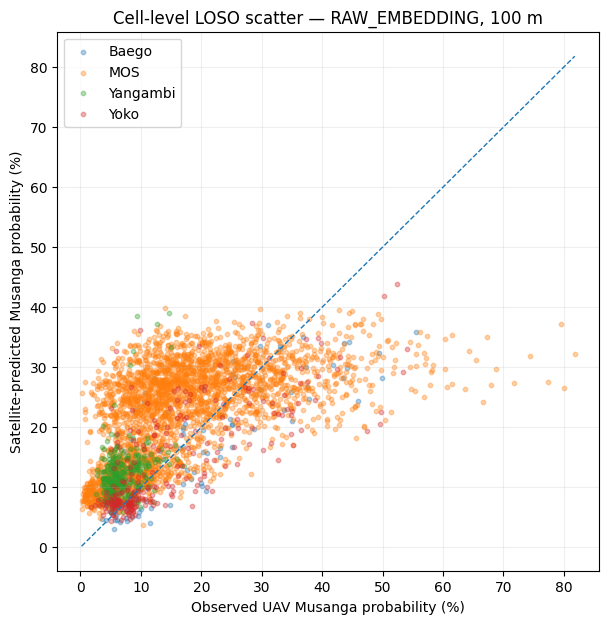


=== Block-mean scatter summary | family=RAW_EMBEDDING | scale=100 m ===


,site,n_blocks,R2_blocks,MAE_pp_blocks,RMSE_pp_blocks,bias_pp_blocks
0,Baego,15,0.770,3.255,4.052,-1.543
1,MOS,145,0.062,6.507,7.951,5.477
2,Yangambi,25,-9.799,5.955,7.351,5.955
3,Yoko,18,0.663,3.358,4.558,0.087


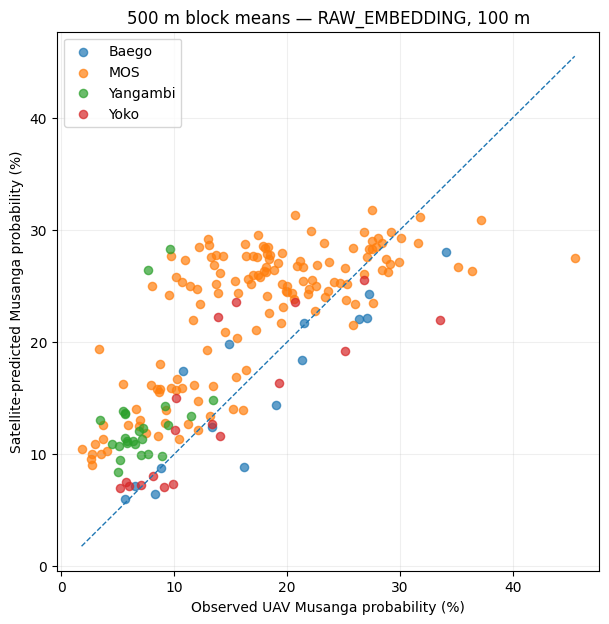

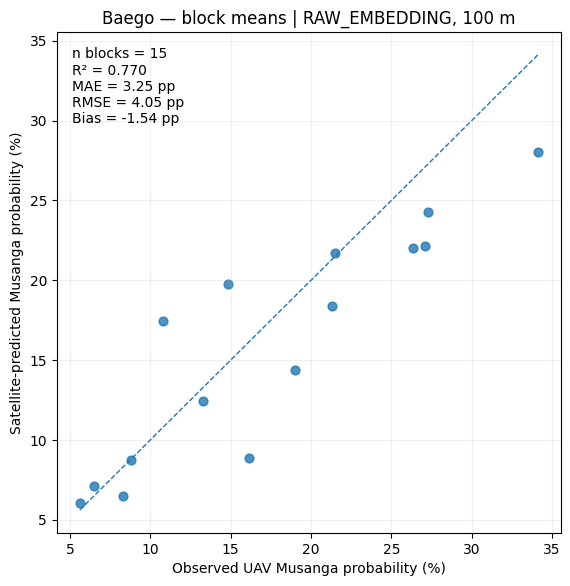

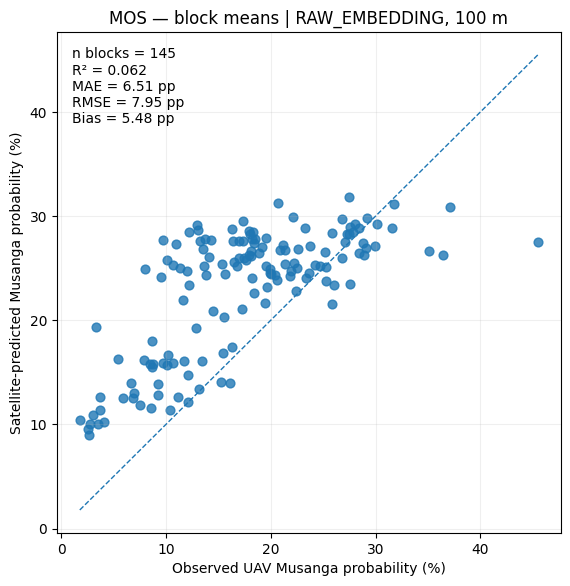

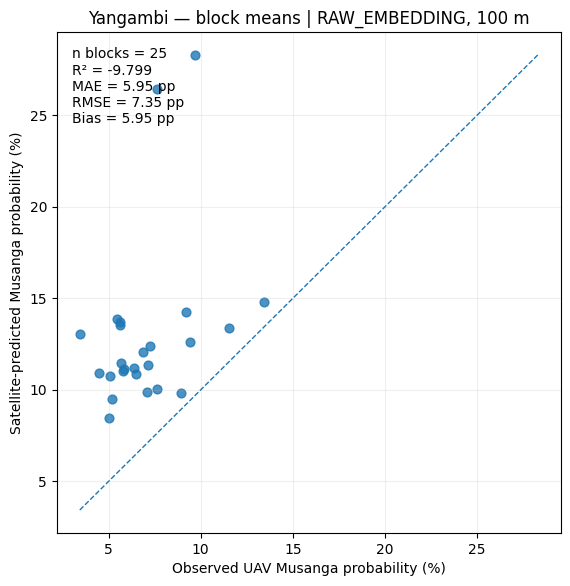

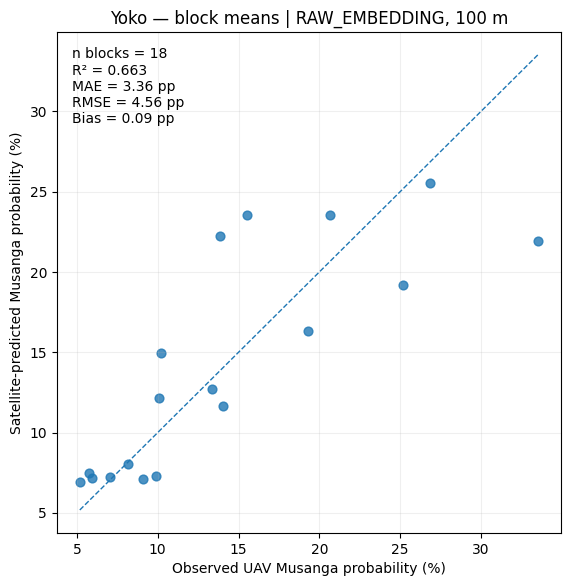

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

PLOT_SCALE = 100
PLOT_FAMILY = "RAW_EMBEDDING"   # try also "RAW" or "EMBEDDING"
MAX_POINTS_PER_SITE = 3000      # for cell-level plotting only
SEED = 42

pred_file = MODEL_DIR / "04_LOSO_cell_predictions.parquet"
assert pred_file.exists(), f"Missing predictions file: {pred_file}"

df = pd.read_parquet(pred_file)

# Keep one configuration
d = df[(df["scale_m"] == PLOT_SCALE) & (df["family"] == PLOT_FAMILY)].copy()
assert len(d) > 0, f"No predictions for scale={PLOT_SCALE}, family={PLOT_FAMILY}"

# Basic checks
required = ["site", "uav_probability", "satellite_pred_prob", "block_id"]
missing = [c for c in required if c not in d.columns]
assert not missing, f"Missing columns: {missing}"

# Convert to percentage points for easier reading
d["obs_pp"] = 100 * d["uav_probability"]
d["pred_pp"] = 100 * d["satellite_pred_prob"]

# ---------- summary table ----------
rows = []
for site, g in d.groupby("site"):
    rows.append({
        "site": site,
        "n_cells": len(g),
        "n_blocks": g["block_id"].nunique(),
        "R2_cells": r2_score(g["obs_pp"], g["pred_pp"]),
        "MAE_pp_cells": mean_absolute_error(g["obs_pp"], g["pred_pp"]),
        "RMSE_pp_cells": np.sqrt(mean_squared_error(g["obs_pp"], g["pred_pp"])),
        "bias_pp_cells": (g["pred_pp"] - g["obs_pp"]).mean()
    })

summary = pd.DataFrame(rows).sort_values("site").reset_index(drop=True)
print(f"\n=== LOSO scatter summary | family={PLOT_FAMILY} | scale={PLOT_SCALE} m ===")
display(summary.round(3))

# ---------- overall cell-level scatter (sampled) ----------
parts = []
for site, g in d.groupby("site"):
    if len(g) > MAX_POINTS_PER_SITE:
        g = g.sample(MAX_POINTS_PER_SITE, random_state=SEED)
    parts.append(g)
plot_df = pd.concat(parts, ignore_index=True)

mn = min(plot_df["obs_pp"].min(), plot_df["pred_pp"].min())
mx = max(plot_df["obs_pp"].max(), plot_df["pred_pp"].max())

fig, ax = plt.subplots(figsize=(7, 7))
for site, g in plot_df.groupby("site"):
    ax.scatter(g["obs_pp"], g["pred_pp"], s=10, alpha=0.35, label=site)
ax.plot([mn, mx], [mn, mx], "--", linewidth=1)
ax.set_xlabel("Observed UAV Musanga probability (%)")
ax.set_ylabel("Satellite-predicted Musanga probability (%)")
ax.set_title(f"Cell-level LOSO scatter — {PLOT_FAMILY}, {PLOT_SCALE} m")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

# ---------- block-level scatter ----------
block = (
    d.groupby(["site", "block_id"], as_index=False)
     .agg(obs_pp=("obs_pp", "mean"),
          pred_pp=("pred_pp", "mean"),
          n_cells=("obs_pp", "size"))
)

rows_block = []
for site, g in block.groupby("site"):
    rows_block.append({
        "site": site,
        "n_blocks": len(g),
        "R2_blocks": r2_score(g["obs_pp"], g["pred_pp"]) if len(g) > 1 else np.nan,
        "MAE_pp_blocks": mean_absolute_error(g["obs_pp"], g["pred_pp"]),
        "RMSE_pp_blocks": np.sqrt(mean_squared_error(g["obs_pp"], g["pred_pp"])),
        "bias_pp_blocks": (g["pred_pp"] - g["obs_pp"]).mean()
    })

block_summary = pd.DataFrame(rows_block).sort_values("site").reset_index(drop=True)
print(f"\n=== Block-mean scatter summary | family={PLOT_FAMILY} | scale={PLOT_SCALE} m ===")
display(block_summary.round(3))

mn = min(block["obs_pp"].min(), block["pred_pp"].min())
mx = max(block["obs_pp"].max(), block["pred_pp"].max())

fig, ax = plt.subplots(figsize=(7, 7))
for site, g in block.groupby("site"):
    ax.scatter(g["obs_pp"], g["pred_pp"], s=35, alpha=0.7, label=site)
ax.plot([mn, mx], [mn, mx], "--", linewidth=1)
ax.set_xlabel("Observed UAV Musanga probability (%)")
ax.set_ylabel("Satellite-predicted Musanga probability (%)")
ax.set_title(f"500 m block means — {PLOT_FAMILY}, {PLOT_SCALE} m")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

# ---------- separate per-site plots ----------
for site, g in block.groupby("site"):
    mn = min(g["obs_pp"].min(), g["pred_pp"].min())
    mx = max(g["obs_pp"].max(), g["pred_pp"].max())

    r2 = r2_score(g["obs_pp"], g["pred_pp"]) if len(g) > 1 else np.nan
    mae = mean_absolute_error(g["obs_pp"], g["pred_pp"])
    rmse = np.sqrt(mean_squared_error(g["obs_pp"], g["pred_pp"]))
    bias = (g["pred_pp"] - g["obs_pp"]).mean()

    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.scatter(g["obs_pp"], g["pred_pp"], s=40, alpha=0.8)
    ax.plot([mn, mx], [mn, mx], "--", linewidth=1)
    ax.set_xlabel("Observed UAV Musanga probability (%)")
    ax.set_ylabel("Satellite-predicted Musanga probability (%)")
    ax.set_title(f"{site} — block means | {PLOT_FAMILY}, {PLOT_SCALE} m")
    ax.grid(alpha=0.2)

    txt = (
        f"n blocks = {len(g)}\n"
        f"R² = {r2:.3f}\n"
        f"MAE = {mae:.2f} pp\n"
        f"RMSE = {rmse:.2f} pp\n"
        f"Bias = {bias:.2f} pp"
    )
    ax.text(0.03, 0.97, txt, transform=ax.transAxes, va="top")
    plt.show()

## 06 — Independent diagnostics: whole UAV mosaics, annotated circles, and within-site spatial blocks

Three independent questions are evaluated:

**A — Whole orthomosaics:** apply **out-of-site** satellite models to full site mosaics; compare their predictions to native-UAV-aggregated pseudo-reference fractions wherever ≥90% of each grid cell contains valid UAV RGB. This is an accurate accounting of *satellite reproduction of the UAV U-Net*, not an independently observed ecological accuracy estimate. Report per-mosaic and site summaries, with MOS mosaics not treated as three independent forests.

**B — Original exhaustive circles:** use the **site-held-out satellite maps** to predict Musanga fractions over the 30 polygon reference circles. Compare against NB02B's original observed polygon cover fractions; use a 4× supersampling of circle intersections to avoid counting all boundary cells as fully inside. Entire circles were excluded (with 100 m buffers) from satellite pseudo-label training, and the held-out site was excluded for LOSO. Nevertheless, the underlying UAV pseudo-target model was trained on all 30 circles, and the annotation dataset was previously used for model selection; these circle checks are supporting evidence, not untouched final tests.

**C — Within-site blocked test:** on the same off-circle pseudo-reference table, withhold entire 500 m blocks and discard training points within 100 m of withheld blocks. Test local generalization separately from unseen-site transfer. Avoid fitting a model on satellite pixels spatially adjacent to the held-out group.


In [16]:
from scipy.ndimage import binary_dilation
from rasterio.windows import from_bounds,transform as window_transform
from rasterio.features import rasterize

def full_mosaic_oof_metrics(scale,family):
    rows=[]
    for site in SITES:
        opath=MODEL_DIR/f"oof_{family}_{site}_{scale}m.tif"
        if not opath.exists():continue
        with rasterio.open(opath) as sat:
            for mosaic,q in SOURCES.items():
                if q["site"]!=site:continue
                target=agg_file(mosaic,scale)
                if not target.exists():continue
                with rasterio.open(target) as uav:
                    assert sat.transform==uav.transform and sat.crs==uav.crs
                    # S2-site grids are smaller than native UAV mosaics, safe to read
                    # per target-scale raster. Keep source mosaics untouched.
                    pred=sat.read()
                    obs=uav.read()
                for j,(label,band) in enumerate((("probability",0),("cover",1))):
                    p=pred[band]
                    y=obs[band]
                    valid=(obs[2]>=MIN_UAV_COVERAGE)&(y>=0)&(y<=1)&(p>=0)&(p<=1)
                    if int(valid.sum())<3:continue
                    rows.append(regression_metrics(y[valid],p[valid],
                          site,scale,family,label,"full_mosaic_oof",
                          blocks=np.nan)|dict(mosaic=mosaic,
                          valid_ha=float(valid.sum()*scale*scale/10000)))
    return rows

def circle_reference_metrics(scale,family):
    rows=[]
    baseline_csv=BASE/"02B_spatialCV_all30_paired.csv" if "BASE" in globals() else (
        ROOT/"Outputs/V3/02B_spatial3fold_no_MOS34/02B_spatialCV_all30_paired.csv")
    raw=pd.read_csv(baseline_csv).query("model == 'M2'")
    assert len(raw)==30 and raw.circle_id.is_unique
    indexed=raw.set_index("circle_id")
    for site in SITES:
        predfile=MODEL_DIR/f"oof_{family}_{site}_{scale}m.tif"
        if not predfile.exists():continue
        records=links.loc[links.site==site]
        with rasterio.open(predfile) as ds:
            for item in records.itertuples(index=False):
                cid=int(item.circle_id)
                polygon=ALL_CIRCLES.iloc[cid:cid+1].to_crs(ds.crs).geometry.iloc[0]
                bb=polygon.bounds
                win=from_bounds(*bb,transform=ds.transform)
                win=win.round_offsets().round_lengths()
                left=max(0,int(win.col_off));top=max(0,int(win.row_off))
                right=min(ds.width,int(win.col_off+win.width+2))
                bottom=min(ds.height,int(win.row_off+win.height+2))
                if right<=left or bottom<=top:continue
                win=Window(left,top,right-left,bottom-top)
                aff=window_transform(win,ds.transform)
                # 4× sub-cell coverage weights, rather than binary all_touched.
                k=4;h=int(win.height);w=int(win.width)
                coarse=rasterize([(polygon,1)],out_shape=(h*k,w*k),
                    transform=aff*Affine.scale(1/k,1/k),fill=0,
                    dtype="uint8").reshape(h,k,w,k).mean(axis=(1,3))
                mass=float(coarse.sum())
                if mass<=0:continue
                z=ds.read(window=win)
                valid=(z[0]>=0)&(z[0]<=1)&(z[1]>=0)&(z[1]<=1)
                fraction=float((coarse*valid).sum()/mass)
                if fraction<0.75:
                    print("LOW CIRCLE SAT COVERAGE",site,cid,
                          round(fraction,3),flush=True)
                    continue
                weight=coarse*valid
                obs=float(indexed.loc[cid,"observed_fraction"])
                pred_prob=100*float((z[0]*weight).sum()/weight.sum())
                pred_cover=100*float((z[1]*weight).sum()/weight.sum())
                rows.append(dict(site=site,circle_id=cid,scale_m=scale,
                    family=family,observed_cover_pp=obs,
                    satellite_prob_cover_pp=pred_prob,
                    satellite_binary_cover_pp=pred_cover,
                    satellite_circle_supported_fraction=fraction,
                    prob_abs_error_pp=abs(pred_prob-obs),
                    binary_abs_error_pp=abs(pred_cover-obs)))
    return rows

def blocked_within_site(scale,family,site):
    fams=FEATURE_COMBINATIONS[family];cols=get_columns(fams)
    path=SAMPLE_DIR/f"{site}_{scale}m_samples.parquet"
    if not path.exists():return []
    data=pd.read_parquet(path)
    if not all(c in data.columns for c in cols):return []
    # All annotated circles (plus buffers) remain excluded from this fitting task.
    data=data.loc[~data.exclude_circles].dropna(
        subset=cols+list(TARGETS.values())).copy()
    if len(data)<200 or data.block_id.nunique()<8:return []
    blocks=data[["block_id","block_x","block_y"]].drop_duplicates()
    rng=np.random.default_rng(SEED04+scale+sum(map(ord,site)))
    held=set(rng.choice(blocks.block_id.to_numpy(),
             size=max(2,round(0.20*len(blocks))),replace=False))
    test=data.loc[data.block_id.isin(held)].copy()
    train=data.loc[~data.block_id.isin(held)].copy()
    # Remove samples within 100m of ANY withheld block boundaries.
    for row in blocks.loc[blocks.block_id.isin(held)].itertuples():
        x0=row.block_x*SPATIAL_BLOCK_M
        y0=row.block_y*SPATIAL_BLOCK_M
        near=((train.x>=x0-BLOCK_BUFFER_M)&
              (train.x<(x0+SPATIAL_BLOCK_M+BLOCK_BUFFER_M))&
              (train.y>=y0-BLOCK_BUFFER_M)&
              (train.y<(y0+SPATIAL_BLOCK_M+BLOCK_BUFFER_M)))
        train=train.loc[~near]
    if len(train)<150 or len(test)<30:return []
    assert set(train.block_id).isdisjoint(set(test.block_id))
    train=balanced_rows(train,MAX_TRAIN_SITE,SEED04)
    test=balanced_rows(test,MAX_TEST_SITE,SEED04)
    out=[]
    for target,col in TARGETS.items():
        model=fitted_model()
        model.fit(train[cols].to_numpy("float32"),train[col].to_numpy("float32"))
        preds=np.clip(model.predict(test[cols].to_numpy("float32")),0,1)
        out.append(regression_metrics(test[col],preds,site,scale,
            family,target,"WITHIN_SITE_BLOCKED_500M_100M_BUFFER",
            test.block_id.nunique()))
    return out

# Evaluations run only after LOSO out-of-fold site maps have been created.
RUN_DIAGNOSTICS=True
if RUN_DIAGNOSTICS:
    full_rows=[];circle_rows=[];block_rows=[]
    for scale in BENCHMARK_SCALES:
        for family in BENCHMARK_FAMILIES:
            full_rows.extend(full_mosaic_oof_metrics(scale,family))
            circle_rows.extend(circle_reference_metrics(scale,family))
            for site in SITES:
                block_rows.extend(blocked_within_site(scale,family,site))
        if full_rows:pd.DataFrame(full_rows).to_csv(QA_DIR/"04_full_mosaic_oof_metrics.csv",index=False)
        if circle_rows:pd.DataFrame(circle_rows).to_csv(QA_DIR/"04_circle_OOF_predictions.csv",index=False)
        if block_rows:pd.DataFrame(block_rows).to_csv(QA_DIR/"04_within_site_blocked_metrics.csv",index=False)
    if circle_rows:
        circles_out=pd.DataFrame(circle_rows)
        summarized=(circles_out.groupby(["scale_m","family","site"])
            .agg(n_circles=("circle_id","size"),
                 prob_MAE_pp=("prob_abs_error_pp","mean"),
                 threshold_MAE_pp=("binary_abs_error_pp","mean"))
            .reset_index())
        summarized.to_csv(QA_DIR/"04_circle_site_summary.csv",index=False)
        display(summarized.round(3))
    if full_rows:display(pd.DataFrame(full_rows).round(3))
    if block_rows:display(pd.DataFrame(block_rows).round(3))


LOW CIRCLE SAT COVERAGE MOS 23 0.722
LOW CIRCLE SAT COVERAGE MOS 23 0.722
LOW CIRCLE SAT COVERAGE MOS 23 0.722
LOW CIRCLE SAT COVERAGE Yangambi 16 0.671
LOW CIRCLE SAT COVERAGE Yangambi 16 0.671
LOW CIRCLE SAT COVERAGE Yangambi 16 0.671


,scale_m,family,site,n_circles,prob_MAE_pp,threshold_MAE_pp
0,10,EMBEDDING,Baego,7,14.492,16.928
1,10,EMBEDDING,MOS,11,24.929,29.527
2,10,EMBEDDING,Yangambi,7,5.877,7.227
3,10,EMBEDDING,Yoko,5,9.260,13.371
4,10,RAW,Baego,7,16.314,18.108
5,10,RAW,MOS,11,18.728,21.397
6,10,RAW,Yangambi,7,5.760,5.958
7,10,RAW,Yoko,5,13.489,17.420
8,10,RAW_EMBEDDING,Baego,7,13.708,14.428
9,10,RAW_EMBEDDING,MOS,11,16.596,16.267


,site,scale_m,family,target,validation,n_cells,n_spatial_blocks,R2,MAE_pp,RMSE_pp,bias_pp,mosaic,valid_ha
0,Baego,10,RAW,probability,full_mosaic_oof,13417,NaN,0.316,12.661,17.809,-1.383,Baego.tif,134.17
1,Baego,10,RAW,cover,full_mosaic_oof,13417,NaN,0.271,13.816,22.282,-1.376,Baego.tif,134.17
2,MOS,10,RAW,probability,full_mosaic_oof,195857,NaN,0.130,13.808,19.062,3.731,Mos_1_2_transparent_mosaic_group1_georef.tif,1958.57
3,MOS,10,RAW,cover,full_mosaic_oof,195857,NaN,-0.009,16.685,25.140,5.814,Mos_1_2_transparent_mosaic_group1_georef.tif,1958.57
4,MOS,10,RAW,probability,full_mosaic_oof,96707,NaN,-0.193,18.926,23.241,8.821,Mos_5_6_transparent_mosaic_group1_georef.tif,967.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,MOS,100,RAW_EMBEDDING,cover,full_mosaic_oof,929,NaN,-0.776,14.635,16.602,11.187,Mos_5_6_transparent_mosaic_group1_georef.tif,929.00
146,Yangambi,100,RAW_EMBEDDING,probability,full_mosaic_oof,316,NaN,-5.843,5.460,6.733,5.282,Yangambi_georef.tif,316.00
147,Yangambi,100,RAW_EMBEDDING,cover,full_mosaic_oof,316,NaN,-41.382,10.249,11.230,10.249,Yangambi_georef.tif,316.00
148,Yoko,100,RAW_EMBEDDING,probability,full_mosaic_oof,262,NaN,0.556,5.349,7.565,-0.711,Yoko_kvo_georef.tif,262.00


,site,scale_m,family,target,validation,n_cells,n_spatial_blocks,R2,MAE_pp,RMSE_pp,bias_pp
0,Baego,10,RAW,prob,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,2149,4,0.206,10.672,15.222,1.318
1,Baego,10,RAW,cover,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,2149,4,0.161,10.422,18.266,0.857
2,MOS,10,RAW,prob,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,7218,29,0.247,13.138,18.048,-0.398
3,MOS,10,RAW,cover,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,7218,29,0.194,14.468,23.293,0.102
4,Yangambi,10,RAW,prob,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,4153,6,-0.230,5.860,7.819,2.338
...,...,...,...,...,...,...,...,...,...,...,...
91,MOS,100,RAW,cover,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,507,29,0.458,6.707,10.169,-1.306
92,MOS,100,EMBEDDING,prob,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,507,29,0.611,5.506,7.857,-1.133
93,MOS,100,EMBEDDING,cover,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,507,29,0.506,6.185,9.709,-1.700
94,MOS,100,RAW_EMBEDDING,prob,WITHIN_SITE_BLOCKED_500M_100M_BUFFER,507,29,0.625,5.393,7.713,-0.752


## 07 — Compare aggregation scales and feature families, audit transfer, choose production strategy

The key scientific question is whether aggregating Musanga from UAV-scale to 20–100 m makes its relation to satellite reflectance/texture/embeddings more predictable. Plot **LOSO fractional-cover error versus pixel size** by predictor family, show cell-level and site-level summaries, and separately show annotated-circle MAE and within-site blocked errors. Do not select a scale using raw pixel counts (spatial pseudo-replication); base interpretation on four independent held-out forest-site scores and their variability. A 10 m map with low reported cell MAE may still contain no meaningful ecological-scale transfer compared with 50–100 m.

**Recommended model-development sequence:** (1) fixed HistGradientBoosting benchmark across families/scales; (2) test annual S2 versus quarterly S2 versus embeddings versus fusion on matched support; (3) fix one feature family and scale based on **site-level** mean LOSO and circle validation; (4) optionally compare Ridge/Random Forest after the first baseline is complete, with hyperparameters tuned only within training sites; (5) refit on all four sites' off-circle pseudo-labels for production maps. Keep outer LOSO test metrics untouched. For an additional independent ecological test, use new field plots or new manually interpreted circles that have never influenced UAV model training or satellite model selection.

**Caveats:** S2 quarter composites include variable image counts; annotate annual clear counts and seasonal gaps. Yoko 2020 may have a different phenological/cloud record than 2024 sites. If the MOS mosaics overlap, site-grid deduplication prevents repeated sampling but reported full-mosaic errors still require geographic overlap assessment. Yangambi's pseudo-target depends on the native M2 that performed poorly there; agreement with it may not imply accurate Musanga fractions.


In [8]:
import matplotlib.pyplot as plt
def plot_scale_benchmark():
    path=MODEL_DIR/"04_LOSO_metrics.csv"
    if not path.exists():
        print("No completed LOSO benchmark yet; run Sections 02–06 after NB03.")
        return
    data=pd.read_csv(path)
    data=data[data.target=="prob"].copy()
    # Site-level mean is the replicated unit, not raw pixel counts.
    table=data.groupby(["family","scale_m"]).agg(
        sites=("site","nunique"),site_mean_MAE_pp=("MAE_pp","mean"),
        site_sd_MAE_pp=("MAE_pp","std"),
        site_mean_R2=("R2","mean")).reset_index()
    print("Leave-one-site-out performance, site macro-average:")
    display(table.round(3))
    fig,ax=plt.subplots(figsize=(9,5))
    for family,part in table.groupby("family"):
        part=part.sort_values("scale_m")
        ax.plot(part.scale_m,part.site_mean_MAE_pp,"o-",label=family)
    ax.set(xlabel="Aggregation scale (m)",ylabel="Site-macro MAE (percentage points)",
           title="Does direct UAV-to-satellite aggregation improve transfer?")
    ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.savefig(QA_DIR/"04_LOSO_scale_curve.png",dpi=180,bbox_inches="tight")
    plt.show();plt.close(fig)
    circle=QA_DIR/"04_circle_site_summary.csv"
    if circle.exists():
        c=pd.read_csv(circle)
        display(c.sort_values("prob_MAE_pp").head(20).round(3))
    blocked=QA_DIR/"04_within_site_blocked_metrics.csv"
    if blocked.exists():
        b=pd.read_csv(blocked)
        display(b.groupby(["family","scale_m","target"]).agg(
            mean_MAE_pp=("MAE_pp","mean"),sites=("site","nunique")).round(3))
plot_scale_benchmark()
print("V3 NB04 workflow implemented; Earth Engine exports and modelling require Colab execution.")


No completed LOSO benchmark yet; run Sections 02–06 after NB03.
V3 NB04 workflow implemented; Earth Engine exports and modelling require Colab execution.


## 08 — Optional production satellite model after validation is frozen

Only after examining LOSO **site-level** and annotated-circle results, select one physical support scale and feature family. Fit the **same fixed regressor** using all four sites' available pseudo-target cells *outside* the annotated-circle buffers and save full-extent prediction rasters at the selected scale. These are final production maps, not an additional validation fold. Use site-LOSO metrics as the transfer estimate, and explicitly document all chosen scale/family decisions (they were chosen after exploratory tests). For new forests without UAV reference, the chosen model predicts Musanga cover fraction from the satellite bands alone. Existing held-out-site maps are never overwritten.


In [9]:
# DO NOT switch this on before reviewing site-LOSO + circle diagnostics.
RUN_FINAL_SATELLITE_MODEL=False
CHOSEN_SCALE_M=30
CHOSEN_FAMILY="RAW_EMBEDDING"
if RUN_FINAL_SATELLITE_MODEL:
    assert (MODEL_DIR/"04_LOSO_metrics.csv").exists(),(
        "Complete independent site validation before final refit")
    assert CHOSEN_SCALE_M in BENCHMARK_SCALES
    assert CHOSEN_FAMILY in FEATURE_COMBINATIONS
    fams=FEATURE_COMBINATIONS[CHOSEN_FAMILY]
    columns=get_columns(fams)
    training=[]
    for site in SITES:
        file=SAMPLE_DIR/f"{site}_{CHOSEN_SCALE_M}m_samples.parquet"
        assert file.exists(),("Missing final training site",site)
        frame=pd.read_parquet(file)
        assert all(c in frame for c in columns),("Missing features",site)
        frame=frame.loc[~frame.exclude_circles].dropna(
            subset=columns+list(TARGETS.values()))
        assert len(frame)>300,("Too few training cells",site)
        training.append(balanced_rows(frame,MAX_TRAIN_SITE,SEED04+CHOSEN_SCALE_M))
    all_data=pd.concat(training,ignore_index=True)
    assert set(all_data.site)==set(SITES)
    selection=dict(pipeline="NB04_final_satellite_v1",
        family=CHOSEN_FAMILY,scale_m=CHOSEN_SCALE_M,columns=columns,
        training_sites=sorted(SITES),training_cells_per_site=all_data.groupby("site").size().to_dict(),
        learning_recipe="Fixed HistGradientBoostingRegressor no tuning",
        pseudo_target_model=MODE,annotation_circle_buffer_m=BUFFER_CIRCLE_M,
        seed=SEED04)
    key=hashlib.sha256(json.dumps(selection,sort_keys=True).encode()).hexdigest()[:20]
    root=MODEL_DIR/f"production_{CHOSEN_FAMILY}_{CHOSEN_SCALE_M}m_{key}"
    assert not root.exists(),("Final model already exists; inspect instead of overwriting",root)
    root.mkdir(parents=True)
    (root/"selection.json").write_text(json.dumps(selection,indent=2))
    models={}
    for target,yname in TARGETS.items():
        estimator=fitted_model()
        estimator.fit(all_data[columns].to_numpy("float32"),
                      all_data[yname].to_numpy("float32"))
        models[target]=estimator
        joblib.dump(estimator,root/f"{target}_model.joblib")
    # Full satellite coverage; native UAV footprint is NOT required at prediction time.
    for site in SITES:
        feature_data=_feature_grid(site,CHOSEN_SCALE_M,fams)
        assert feature_data is not None,site
        cube,g=feature_data
        good=(np.isfinite(cube).all(axis=0)&(
            roi_fraction_grid(site,g)>=ROI_MIN_FRACTION)).ravel()
        ids=np.flatnonzero(good)
        flat=cube.reshape(cube.shape[0],-1)
        predictions=np.full((2,flat.shape[1]),-9999,"float32")
        for offset in range(0,len(ids),30000):
            take=ids[offset:offset+30000]
            x=flat[:,take].T
            for i,target in enumerate(("prob","cover")):
                predictions[i,take]=np.clip(models[target].predict(x),0,1)
        path=root/f"{site}_satellite_Musanga_fraction_{CHOSEN_SCALE_M}m.tif"
        with rasterio.open(path,"w",driver="GTiff",width=g["width"],height=g["height"],
             count=2,dtype="float32",crs=g["crs"],transform=Affine(*g["transform"]),
             nodata=-9999,tiled=True,blockxsize=256,blockysize=256,
             compress="deflate",predictor=3,bigtiff="YES") as ds:
            ds.write(predictions.reshape(2,g["height"],g["width"]))
            ds.set_band_description(1,"expected_Musanga_cover_from_mean_UAV_probability")
            ds.set_band_description(2,"predicted_fraction_of_UAV_pixels_p_ge_0p5")
            ds.update_tags(MODEL_KEY=key,SITE=site,
                           TRAINED_ON_ALL_SITES="YES",VALIDATION="SEE_LOSO_METRICS")
        print("SATELLITE PRODUCTION MAP",path,flush=True)
    print("All final satellite maps complete:",root)
